### Fill in group number and member names:

In [1]:
GROUP = "15"
NAME1 = "Aaron O'Malley"
NAME2 = "Gustav Fohlstedt"

# Optimization for learning - FRTN50

## Assignment 2

The purpose of this assignment is to empirically explore some convergence and implicit regularization properties of the stochastic gradient decent (SGD) method and some of its variants. These properties are mainly explored by considering simple polynomial fitting problems in $\mathbb{R}$ to facilitate easy comparison with known theoretical results and easy visualization. We will also compare the same fitting problem with multi-layer perceptrons also known as fully connected feedforward neural networks.

Below are the tasks that you need to solve. Keep this in mind:
- Carefully motivate every step in your calculations.
- Use figures and tables to motivate your answers.
- Figures must have appropriately labeled axes and must be referenced in the main text.
- Your code should be written in a quite general manner, i.e., if a question is slightly modified, it should only require slight modifications in your code as well. 
- Comment your code well. 
- Make sure you plot in such a way that small quantities are visible. In particular, use log-linear plots, where the quantity that should go to $0$ is on the $y$-axis using logarithmic scale, and the iteration number $k$ on the $x$-axis using linear scale.
- What you need to submit to Canvas:
    - This jupyter notebook containing your solutions.
    - An exported pdf version of the jupyter notebook.

---
### Exercise 1: Polynomial fitting in $\mathbb{R}$ using least squares with a polynomial feature map

Consider fitting the points $\{(x_{i},y_{i})\}_{i=1}^{N}\subseteq\mathbb{R}\times\mathbb{R}$ to a polynomial model $m(\cdot;\theta):\mathbb{R}\rightarrow\mathbb{R}$ using the method of least squares. Here, the model is given by

$$
\begin{align}
    m(x;\theta) = \theta^{T}\phi(x)
\end{align}
$$

where $\theta\in\mathbb{R}^{n+1}$ is the parameter of the model and $\phi:\mathbb{R}\rightarrow\mathbb{R}^{n+1}$ is a polynomial feature map given by

$$
\begin{align}
    \phi(x) = 
    \begin{bmatrix}
    1 \\
    x \\
    \vdots \\
    x^{n}
    \end{bmatrix}
\end{align}
$$
for each $x\in\mathbb{R}$.

I.e. $m(\cdot;\theta)$ is a polynomial (in particular nonlinear) model of degree $n$ and is linear in the parameter $\theta$. If we compare to deep learning, the model $m(\cdot;\theta)$ would have a specific structure but would be nonlinear in the parameter $\theta$ in general.

The method of least squares involves solving the optimization problem

$$
\begin{equation}\label{eq:1}\tag{1}
\begin{aligned}
& \underset{\theta\in\mathbb{R}^{n+1}}{\mathrm{minimize}}
& & \frac{1}{N} \sum_{i=1}^{N}(m(x_{i};\theta) - y_{i})^{2} = \frac{1}{N} \sum_{i=1}^{N}\underbrace{(\theta^{T}\phi(x_{i}) - y_{i})^{2}}_{=f_{i}(\theta)} = \frac{1}{N} \sum_{i=1}^{N}f_{i}(\theta) 
\end{aligned}
\end{equation}
$$

giving an optimal point $\theta^{*}\in\mathbb{R}^{n+1}$, and letting $m(\cdot;\theta^{*})$ be the fitted model. If we let 

$$
\begin{align}
    X = 
    \begin{bmatrix}
    \phi(x_{1})^{T} \\
    \vdots \\
    \phi(x_{N})^{T} 
    \end{bmatrix}\in\mathbb{R}^{N \times (n+1)},  \quad \text{ and } \quad
    Y = 
    \begin{bmatrix}
    y_{1} \\
    \vdots \\
    y_{N}
    \end{bmatrix}\in\mathbb{R}^{N},
\end{align}
$$

optimization problem $\eqref{eq:1}$ can be written as 

$$
\begin{equation}\label{eq:2}\tag{2}
\begin{aligned}
& \underset{\theta\in\mathbb{R}^{n+1}}{\mathrm{minimize}}
& & \frac{1}{N} \left\lVert X\theta - Y \right\rVert_{2}^{2} = f(\theta).
\end{aligned}
\end{equation}
$$

Since the model $m(\cdot;\theta)$ is linear in $\theta$, the function $f$ is convex in $\theta$. This is not the case in deep learning, since the model $m(\cdot;\theta)$ would not be linear in $\theta$ in general.

If the points $x_{i}$ in $\{(x_{i},y_{i})\}_{i=1}^{N}$ are distinct, which is the case in our analysis, it holds that 

$$
\begin{align}
    \text{rank } X = \min(N,n+1).
\end{align}
$$
(See [Vandermonde matrix](https://en.wikipedia.org/wiki/Vandermonde_matrix) for more info.) In particular,
1. if $N < n+1$, optimization problem $\eqref{eq:2}$ is underdetermined, $X X^{T}$ is invertible and there exist $\theta^{*}\in\mathbb{R}^{n+1}$ such that $X\theta^{*} = Y$,
2. if $N > n+1$, optimization problem $\eqref{eq:2}$ is overdetermined and $X^{T} X$ is invertible,
3. if $N = n+1$, both $X X^{T}$ and $X^{T} X$ are invertible and optimization problem $\eqref{eq:2}$ is neither underdetermined nor overdetermined.

You are allowed to assume these facts as given.

---
__a)__ A model is sometimes said to be overparameterized if it has more parameters than data points. By the same token, a model is said to be underparameterized if it has less parameters than data points. 

- Suppose that our model is overparameterized. Which case of 1., 2. and 3. above does this corresponds to? 
- Suppose that our model is underparameterized. Which case of 1., 2. and 3. above does this corresponds to? 

Motivate your answer. It is crucial that you get this right to avoid confusion later.

__Solution:__ 

Suppose that our model is overparameterized. We then have more parameters than datapoints. The pairs $\{(x_{i},y_{i})\}_{i=1}^{N}$ tells that N is the number of datapoints. Furthermore $\theta\in\mathbb{R}^{n+1}$ tells us that we have $n+1$ parameters. Hence, we have $N < n+1$ and this corresponds to case 1.

Similarly, if our model is underparameterized we have fewer parameters than datapoints, i.e. $N > n+1$, which corresponds to case 2.

---
__b)__ Find $\nabla f$, $\nabla f_{i}$ and $\nabla^{2}f$.

Carefully motivate your answer.

__Solution:__ 

We have $f(\theta) = \frac{1}{N} \lVert X\theta - Y \rVert_{2}^{2}$

$\nabla f(\theta) = X^T\nabla g(X\theta) = \frac{2}{N}X^T(X\theta - Y) = \frac{2}{N}(X^TX\theta - X^TY)$

$\nabla f_i(\theta) = (\theta^T\phi(x_i) - y_i)^2= 2(\theta^T \phi(x_i)- y_i)\phi(x_i)$

Using the results from $\nabla f(\theta)$ we get

$\nabla^2 f(\theta) = \nabla(\frac{2}{N}(X^TX\theta - X^TY)) = \frac{2}{N}( X^TX) $


---
__c)__ Since $f$ is convex and differentiable, all optimal points $\theta^{*}\in\mathbb{R}^{n+1}$ to the least squares problem are fully characterized by the condition that $X\theta^{*} = Y$.

$$
\begin{align}
    \nabla f (\theta^{*}) = 0.
\end{align}
$$

Suppose that the least squares problem is underparameterized. 

- Show that there exists a solution $\theta^{*}$
- Conclude that it is unique
- Find a expression for $f(\theta^{*})$

Carefully motivate your answer.

__Solution:__ 

We know from 1b) that $\nabla f(\theta^*) = 0 \iff X^TX\theta^* = X^TY$, and since the problem is underparameterize and since $X^T X $ is invertible from fact 2 we can write
$$
\theta^* = (X^T X)^{-1} X^T Y
$$

Since $X^T X $ is invertible there exist a unique solution 

Inserting $\theta^*$ into $f$ gives

$$
f(\theta^*) = \frac{1}{N} || X(X^T X)^{-1} X^T Y -Y ||_2^2 =  \frac{1}{N} || P Y -Y ||_2^2
$$

with $ P =  X(X^T X)^{-1} X^T $

---
__d)__ Suppose instead that the least squares problem is overparameterized. Let $\theta^{*}\in\mathbb{R}^{n+1}$. Show that $\theta^{*}$ is a solution to the least squares problem if and only if $X\theta^{*} = Y$. I.e. show that:
- If $\theta^{*}$ is a solution to the least squares problem, then $X\theta^{*} = Y$.
- If $X\theta^{*} = Y$, then $\theta^{*}$ is a solution to the least squares problem.

Hence, the solution set is an affine set that can be written as $\Theta^{*}  = \{\theta^{*} \in\mathbb{R}^{n+1}: X\theta^{*}=Y\}$.
- Prove that the set $\Theta^{*}$ is affine.

Carefully motivate your answer.

_Hints:_ Note that $f(\theta)=\frac{1}{N} \left\lVert X\theta - Y \right\rVert_{2}^{2}\geq 0$ for all $\theta\in\mathbb{R}^{n+1}$. Moreover, what can be said in the overparameterized case? What is the definition of an affine set?

__Solution:__

Suppose that $\theta^*$ is a solution. Since the model is overparameterized, fact 1 gives that there exists $\hat\theta \in \mathbb{R}^{n+1}$ such that $X\hat\theta = Y$, and hence $f(\hat\theta) = 0$. Since $\theta^*$ is optimal and $f(\theta) \ge 0$ for all $\theta \in \mathbb{R}^{n+1}$, we get

$$0 \le f(\theta^*) \le f(\hat\theta) = 0,$$

so $f(\theta^*) = \frac{1}{N}\|X\theta^* - Y\|_2^2 = 0$. Since a norm is zero only for the zero vector, $X\theta^* - Y = 0$, i.e., $X\theta^* = Y$.

Suppose that $\theta^* \in \mathbb{R}^{n+1}$ is such that $X\theta^* = Y$. Starting from the expression $X\theta^* = Y $, and multiplying both sides by $X^T$ and using the results from 1b) gives
$$
X^TX\theta^* = X^TY \iff \nabla f(\theta^*) = 0
$$
Which show that $\theta^*$ is a solution.


A set $C$ is affine if $\theta x + (1-\theta)y \in C$ for all $x, y \in C$ and all $\theta \in \mathbb{R}$. Let $\theta_1, \theta_2 \in \Theta^*$ and $\lambda \in \mathbb{R}$, this gives, $X\theta_1 = Y$ and $X\theta_2 = Y$. By linearity of $X$ we have

$$X\big(\lambda\theta_1 + (1-\lambda)\theta_2\big) = \lambda X\theta_1 + (1-\lambda)X\theta_2 = \lambda Y + (1-\lambda)Y = Y,$$

so $\lambda\theta_1 + (1-\lambda)\theta_2 \in \Theta^*$. Hence $\Theta^*$ is affine.




---
__e)__ In the overparameterized case, the null space $\mathcal{N}(X)=\{\theta\in\mathbb{R}^{n+1}:X\theta=0\}$ has dimension $\dim\mathcal{N}(X) = n+1-N >0$. This can be shown using, e.g., the rank–nullity theorem. Suppose that $\hat\theta\in\mathbb{R}^{n+1}$ is some point that satisfies $X\hat\theta = Y$ and that $v\in\mathcal{N}(X)$. 

- Show that $\hat\theta+v$ is a solution to the least squares problem.
- Show that $\hat\theta+\alpha v$ is a solution to the least squares problem for all $\alpha \in \mathbb{R}$. (This follows from from the above but is included to emphasize the fact that, assuming $v\neq 0$, we can add an arbitrary large vector to $\hat\theta$ and it still remains a solution to the the least squares problem.)

As a consequence, note that an another characterization of the set of solutions of the least squares problem is given by $\Theta^{*}  = \{\hat\theta + v : v\in\mathcal{N}(X) \}$. In particular, $\Theta^{*}$ has dimension $\dim\Theta^{*} = n+1-N >0$. Therefore, the more overparameterized (larger $n+1-N$) the problem is, the large the solution set $\Theta^{*}$ becomes. 

- Show that $\Theta^{*}$ and $\{\hat\theta + v : v\in\mathcal{N}(X) \}$ are equal. One way to show this is to show that all elements of $\Theta^{*}$ are in $\{\hat\theta + v : v\in\mathcal{N}(X) \}$, i.e. $\Theta^{*}\subseteq\{\hat\theta + v : v\in\mathcal{N}(X) \}$, and that all elements in $\{\hat\theta + v : v\in\mathcal{N}(X) \}$ are in $\Theta^{*}$, i.e. $\{\hat\theta + v : v\in\mathcal{N}(X) \}\subseteq\Theta^{*}$.

Carefully motivate your answer.

__Solution:__ 

If we take $\theta' = \hat{\theta} + v$, inserting this into $X\theta'$ along with $v \in \mathcal{N}(X) \implies Xv = 0$ gives
$$
X\theta' = X(\hat{\theta} + v) = X\hat{\theta} + Xv = Y + 0 = Y
$$
Therefore $X(\hat{\theta} + v) = Y$ which means it is a solution to the least squares problem from the results in d).

Since $\alpha$ is a scalar we get $\theta' = \hat{\theta} + \alpha v$, inserting this into $X\theta'$ along with $v \in \mathcal{N}(X) \implies Xv = 0$ with the addition of $\alpha$ being a scalar and thus $X\alpha v = \alpha Xv$ gives
$$
X\theta' = X(\hat{\theta} + \alpha v) = X\hat{\theta} + X \alpha v = Y + \alpha Xv = Y + 0 = Y
$$
Therefore $X(\hat{\theta} + \alpha v) = Y$ is also a solution.

Proving $\{\hat\theta + v : v\in\mathcal{N}(X) \}\subseteq\Theta^{*}$: This follows from the proof above since we showed that $X(\hat{\theta} + v) = Y$ which means that $\hat{\theta} + v \in \Theta^*$.

Proving $\Theta^{*}\subseteq\{\hat\theta + v : v\in\mathcal{N}(X) \}$: Let $\theta' \in \Theta^*$. By d) we have $X\theta' = Y$. Define $v = \theta' - \hat\theta$. Then


$$Xv = X\theta' - X\hat\theta = Y - Y = 0,$$

so $v \in \mathcal{N}(X)$ and $\theta' = \hat\theta + v$. Hence $\Theta^* \subseteq \{\hat\theta + v : v \in \mathcal{N}(X)\}$.

Since both inclusions hold, $\Theta^* = \{\hat\theta + v : v \in \mathcal{N}(X)\}$.


---
__f)__ Suppose that the least squares problem is overparameterized. 

Why can we not use the solution from __c)__ in this case?

__Solution:__ 

Because the solution in c) requires that $X^TX$ is invertible. In the overparameterized case $\text{rank}(X^TX) = \text{rank}(X) = N < n+1$, so $X^TX$ is singular and $(X^TX)^{-1}$ does not exist.

---
__g)__ Suppose that the least squares problem is overparameterized. 

We know from __d)__ and __e)__ that the set of all solutions $\Theta^{*}$ is an affine set with infinitely many elements. One way to pick a solution is to start with some candidate point $a\in\mathbb{R}^{n+1}$ and project it onto $\Theta^{*}$. Since $\Theta^{*}$ is closed, convex and nonempty, the projection point exists and is unique, and can be found by solving the optimization problem 

$$
\begin{equation}
\begin{aligned}
& \underset{\theta\in\mathbb{R}^{n+1}}{\mathrm{minimize}}
& &  \frac{1}{2}\left\lVert \theta - a \right\rVert_{2}^{2}\\
& \text{subject to}
& &  \theta \in \Theta^{*}.
\end{aligned}
\end{equation} 
$$ 

We call this the Euclidean projection problem. Another way to write the Euclidean projection problem is 

$$
\begin{equation}
\begin{aligned}
& \underset{\theta\in\mathbb{R}^{n+1}}{\mathrm{minimize}}
& &  \frac{1}{2}\left\lVert \theta - a \right\rVert_{2}^{2} + \iota_{\Theta^{*}}(\theta)
\end{aligned}
\end{equation} 
$$ 


where $\iota_{\Theta^{*}}$ is the indicator function of the set $\Theta^{*}$. By Fermat's rule, $\theta^{*} \in\mathbb{R}^{n+1}$ is an optimal point to the Euclidean projection problem if and only if the optimality condition

$$
\begin{align*}
0 \in \theta^{*} - a + \partial \iota_{\Theta^{*}}(\theta^{*})
\end{align*}
$$

holds, by convexity and since CQ holds. Note that in the exercise compendium, we show that the subdifferential of the indicator function of a set is the normal cone to that set. In particular, in our case we have that 

$$
\begin{align*}
\partial \iota_{\Theta^{*}}(\theta^{*}) &= N_{\Theta^{*}}(\theta^{*}) \\
&= 
\begin{cases}
\left\{s\in\mathbb{R}^{n}: \forall \eta\in \Theta^{*},\, s^{T}(\eta-\theta^{*})\leq 0\right\}   & \text{if } \theta^{*}\in \Theta^{*} \\
\emptyset                                                         & \text{if } \theta^{*}\notin \Theta^{*}
\end{cases} \\
&= 
\begin{cases}
\left\{s\in\mathbb{R}^{n}: \forall v\in \mathcal{N}(X),\, s^{T} v = 0\right\}   & \text{if } \theta^{*}\in \Theta^{*} \\
\emptyset                                                         & \text{if } \theta^{*}\notin \Theta^{*}
\end{cases} \\
&=
\begin{cases}
\mathcal{R}(X^{T})   & \text{if } \theta^{*}\in \Theta^{*} \\
\emptyset                                                         & \text{if } \theta^{*}\notin \Theta^{*}
\end{cases} \\
&=
\begin{cases}
\left\{X^{T}\lambda: \lambda \in \mathbb{R}^{N}\right\}   & \text{if } \theta^{*}\in \Theta^{*} \\
\emptyset                                                         & \text{if } \theta^{*}\notin \Theta^{*}.
\end{cases} 
\end{align*}
$$

If we combine this with the optimality condition above we get that $\theta^{*}$ is an optimal point to the Euclidean projection problem if and only if there exists a $\lambda^{*}\in\mathbb{R}^{N}$ such that 

$$
\begin{align}
    0 = \theta^{*} - a + X^{T}\lambda^{*} \quad \text{ and } \quad X\theta^{*}=Y.
\end{align}
$$ 

Use this last optimality condition to show that $\theta^{*} = a - X^{T}(XX^{T})^{-1}(Xa-Y)$ is the optimal point for the Euclidean projection problem. We also call this $\theta^{*}$ the Euclidean projection (of $a$ onto $\Theta^{*}$).

Carefully motivate your answer.

_Remark:_ We have a generalization: Suppose that $H\in\mathbb{S}^{n+1}_{++}$ and let $\left\lVert \theta \right\rVert_{H}^{2} = \theta^{T}H\theta$. Then the scaled projection problem 

$$
\begin{equation}
\begin{aligned}
& \underset{\theta\in\mathbb{R}^{n+1}}{\mathrm{minimize}}
& &  \frac{1}{2}\left\lVert \theta - a \right\rVert_{H}^{2}\\
& \text{subject to}
& &  \theta \in \Theta^{*}.
\end{aligned}
\end{equation} 
$$ 

has the solution $\theta^{*} = a - H^{-1}X^{T}(X H^{-1}X^{T})^{-1}(X a-Y)$. We call this $\theta^{*}$ the scaled projection (of $a$ onto $\Theta^{*}$). You are not allowed to used this generalization to solve this problem. However, it will be used later.

__Solution:__ 

Inserting $\theta^* = a - X^T\lambda^*$ into the first optimality condition into $X\theta^* = Y$ gives 
$$
X(a - X^T\lambda^*) = Y \iff XX^T\lambda^* = Xa - Y
$$
And since the models is overparameterized, fact 1 gives that $XX^T$ is invertible. Therefore
$$
\lambda^* = (XX^T)^{-1}(Xa - Y)
$$
and inserting this to $\theta^*$ gives

$$
\theta^* = a - X^T(XX^T)^{-1}(Xa - Y)
$$

This shows that $\theta^*$ is the optimal point for the Euclidean projection problem.


---
__h)__ Show that $f:\mathbb{R}^{n+1}\rightarrow\mathbb{R}$ is $\beta$-smooth, i.e., $\nabla f$ is $\beta$-Lipschitz continuous, with constant

$$
\begin{align}
    \beta = \frac{2}{N}\left\lVert X^{T}X \right\rVert_{2}.
\end{align}
$$

Recall that $\nabla f$ is said to be $\beta$-Lipschitz continuous if

$$
\begin{align}
    \left\lVert \nabla f(\theta_{1}) - \nabla f(\theta_{2}) \right\rVert_{2} \leq \beta\left\lVert \theta_{1} - \theta_{2} \right\rVert_{2}, \quad \forall \theta_{1},\theta_{2} \in \mathbb{R}^{n+1}.
\end{align}
$$

_Hint:_ Recall that the spectral norm of a matrix $A\in\mathbb{R}^{l\times m}$ is defined as 

$$
\begin{align}
    \left\lVert A \right\rVert_{2} = \sup_{z\in\mathbb{R}^{m}\setminus\{0\}}\frac{\left\lVert A z \right\rVert_{2}}{\left\lVert z \right\rVert_{2}}.
\end{align}
$$

In particular,

$$
\begin{align}
    \left\lVert A z \right\rVert_{2} \leq \left\lVert A \right\rVert_{2} \left\lVert z \right\rVert_{2}, \quad \forall z \in\mathbb{R}^{m}.
\end{align}
$$

_Remark:_ Note that $\left\lVert \cdot \right\rVert_{2}$ is the __spectral norm__ and not the __Frobenius norm__ - this difference is very important to consider in your implementation below where you will use this $\beta$. Moreover, note that $\beta$ depends on $X$, and will vary as $X$ varies.


__Solution:__ 



From b) we have that

$$
\nabla f(\theta) = \frac{2}{N}\left(X^TX\theta - X^TY\right).
$$

Let $\theta_1, \theta_2 \in \mathbb{R}^{n+1}$. Then

$$
\nabla f(\theta_1) - \nabla f(\theta_2) = \frac{2}{N}\left(X^TX\theta_1 - X^TY\right) - \frac{2}{N}\left(X^TX\theta_2 - X^TY\right) = \frac{2}{N}X^TX(\theta_1 - \theta_2).
$$

Using $\|Az\|_2 \le \|A\|_2\|z\|_2$ with $A = X^TX$ and $z = \theta_1 - \theta_2$ gives

$$
\|\nabla f(\theta_1) - \nabla f(\theta_2)\|_2 = \frac{2}{N}\left\|X^TX(\theta_1 - \theta_2)\right\|_2 \le \frac{2}{N}\|X^TX\|_2\,\|\theta_1 - \theta_2\|_2 = \beta\,\|\theta_1 - \theta_2\|_2.
$$

Since $\theta_1, \theta_2$ were arbitrary, $\nabla f$ is $\beta$-Lipschitz continuous with $\beta = \frac{2}{N}\|X^TX\|_2$, i.e., $f$ is $\beta$-smooth.


---
### Exercise 2: Implementing GD and SGD for polynomial fitting 
_Remark:_ You should solve this exercise using `numpy` primarily.

Consider the data point $\{(x_{i},y_{i})\}_{i=1}^{N}\subseteq\mathbb{R}\times\mathbb{R}$, where $N=7$, below:

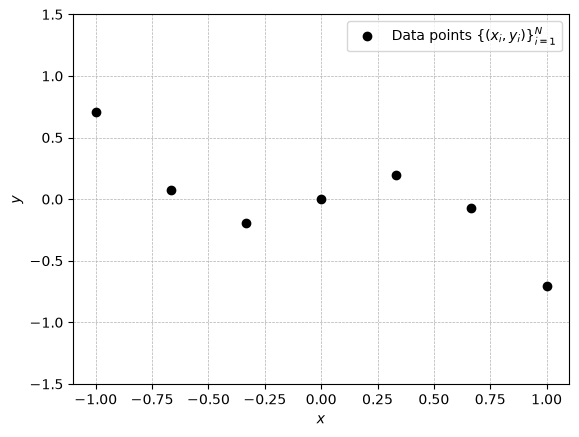

In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

N = 7 # the number of data points
xs = np.linspace(-1, 1, num=N) # the x_i's
ys = np.sin(5*xs)*np.exp(np.abs(2*xs)) / 10 # the y_i's


fig, axes = plt.subplots(dpi=100)
axes.plot(xs,ys,'ko')
axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$'])
axes.set_xlabel('$x$')
axes.set_ylabel('$y$')
axes.grid(linestyle='dashed', linewidth=0.5)
axes.set_ylim([-1.5, 1.5]);

We wish to fit a polynomial model $m(\cdot;\theta)$ of degree $n=3$ (overdetermined) and $n=9$ (underdetermined) to the data points  $\{(x_{i},y_{i})\}_{i=1}^{N}$ by solving optimization problem (1) or equivalently (2) in __Exercise 1__ above.

---
__a)__ First, do this by implementing the GD method. The GD method is given by
- Pick $\theta_{0}\in\mathbb{R}^{n+1}$
- For $k\geq 0$:
    - Set $\theta_{k+1} = \theta_{k} - \gamma_{k} \nabla f(\theta_{k})$ for some $\gamma_{k}>0$.

Pick $\theta_{0} = 0$ as the initial point, and try the constant step size

1. $\gamma_{k} = 1 / \beta$,

and run for $10^5$ iterations. Here, $\beta$ is the smoothness parameter from __Exercise 1__ above. Plot, in log-linear scale, both

- $f(\theta_{k})-f(\theta^{*})$ and
- $f(\overline{\theta}_{k})-f(\theta^{*})$ where $\overline{\theta}_{k} = \frac{1}{k+1}\sum_{l=0}^{k}\theta_{l}$, (Hint: use [sequential average computation](https://math.stackexchange.com/questions/106313/regular-average-calculated-accumulatively))

as a function of iteration number $k$. Give comments:
- Describe any difference between the $n=3$ (overdetermined) and $n=9$ (underdetermined) cases.

_Hint:_ What is $f(\theta^{*})$ in the overdetermined and underdetermined case, respectively? 

__Solution:__ 

For the n=3 (overdetermined) case, it converges quickly to its optimal point as we see in the blue plot, but we know since its overdetermined $f(\theta^*) > 0 $.

For the n=3 (underdetermined) case, converges slower to its optimal point but we know that $f(\theta^*$) = 0 $ from fact 1 inserted into equation 2.

For both choices of $n$, we see that the orange plot converges slower, and for the overdetermined case we obtain a lower value since it converges to to optimal faster


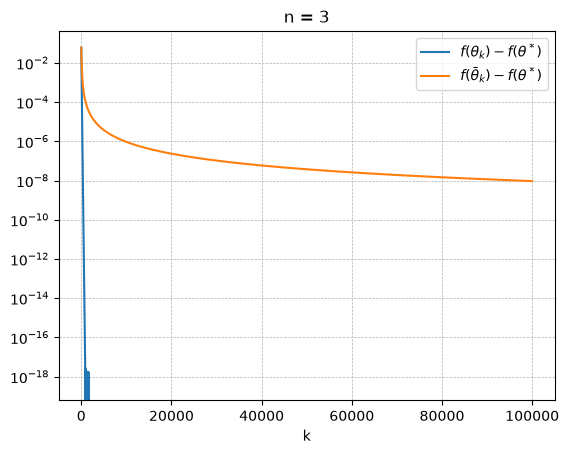

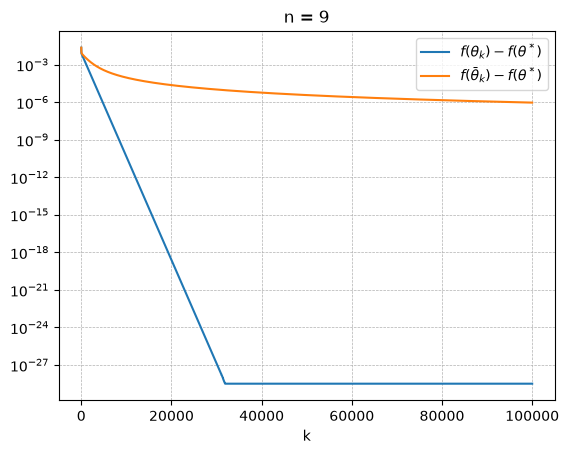

In [3]:
# Write your code here

def f(theta, X ,ys):
    N = len(ys)
    f_theta = 1/N * np.linalg.norm( X@theta - ys, 2)**2
    return f_theta
    
def gradf(theta, X, ys):
    N = len(ys)
    return 2/N * (X.T @ (X @ theta - ys))



def GD(n):
    X = np.vander(xs, n+1, increasing=True)
    beta = 2/N * np.linalg.norm(X.T @ X, 2)
    theta = np.zeros(n+1)
    gamma  = 1/beta
    iterations = int(1e5)
    if N > n+1:
        theta_star = np.linalg.solve(X.T @ X, X.T @ ys)
        f_star = f(theta_star, X, ys)
    else:         
        f_star = 0.0
    
    theta = np.zeros(n+1) # intial guesses
    theta_bar = np.zeros(n+1)
    f_vals, f_bar_vals = [], []
    
    for k in range(iterations):
        theta = theta - gamma * gradf(theta, X, ys) # updating theta for k>=0
        theta_bar = theta_bar + (theta - theta_bar) / (k + 1) # using the tip and with n = k+1 and simplifying the expression
        f_vals.append(f(theta, X, ys) - f_star)
        f_bar_vals.append(f(theta_bar, X, ys) - f_star)

    plt.figure(dpi=100)
    plt.semilogy(f_vals, label=r'$f(\theta_k) - f(\theta^*)$')
    plt.semilogy(f_bar_vals, label=r'$f(\bar\theta_k) - f(\theta^*)$')
    plt.title(f'n = {n}')
    plt.xlabel('k')
    plt.grid(linestyle='dashed', linewidth=0.5)
    plt.legend()
    plt.show()


GD(3)
GD(9)

---
__b)__ Next, do this by implementing the SGD method. The SGD method is given by
- Pick $\theta_{0}\in\mathbb{R}^{n+1}$
- For $k\geq 0$:
    - Pick $i\in\{1,\ldots,N\}$ uniformly at random
    - Set $\theta_{k+1} = \theta_{k} - \gamma_{k} \nabla f_{i}(\theta_{k})$ for some $\gamma_{k}>0$.

Pick $\theta_{0} = 0$ and try the step sizes

1. $\gamma_{k} = \frac{0.1}{\beta}$,
2. $\gamma_{k} = \frac{0.1}{\beta(k+1)}$,
3. $\gamma_{k} = \frac{0.1}{\beta(\lfloor k/1000\rfloor+1)}$, where $\lfloor \cdot \rfloor$ is the floor function,

and run for $10^5 N$ iterations. Plot, in log-linear scale, both

- $f(\theta_{k})-f(\theta^{*})$ and
- $f(\overline{\theta}_{k})-f(\theta^{*})$ where $\overline{\theta}_{k} = \frac{1}{k+1}\sum_{l=0}^{k}\theta_{l}$,

as a function of iteration number $k$. Give comments:
- Does the step sizes matter? 
- Is there a difference between the $n=3$ (overdetermined) and $n=9$ (underdetermined) cases. 
- Which combination worked best? 
- Which combination of $\gamma_{k}$ and $n$ (i.e. overdetermined or underdetermined) corresponds the most to training of neural networks? This question qualitative and has no unique answer.

__Solution:__ 

The step size matters a lot. We see that in the 'g2' case, where the step size decreases with every iteration, SGD does not reach the optimal point, since its blue curve flattens out around $10^{-2}$. For g3, which decreases the step size every 1000 iterations, SGD achieves a lower value than in the g2 case, especially in the overdetermined case.

There is a difference between overdetermined and underdetermined, we can see that the overdetermined systems have a lot of oscillations whereas that is not true for the underdetermined systems. We get the oscillations because the overdetermined systems never fit all points, and thus there are always gradients which causes the osciallations.

The best combination was the constant step size and an underdetermined system, it comes closest to the optimal point with a large margin compared to the other methods.

In neural networks, systems are usually underdetermined since we have many weights and parameters to train, and neural nets usually use fixed step size like g1 or a decreasing learning rate similar to g3, g2 decreases too fast to be used in neural network training.


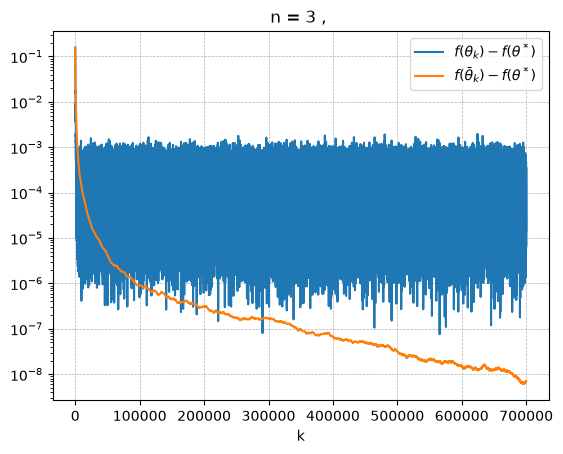

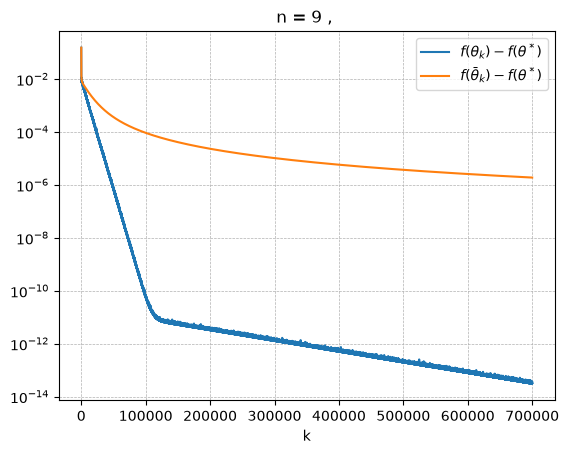

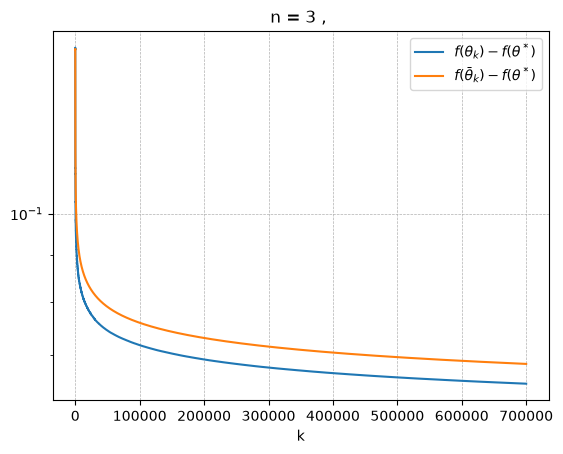

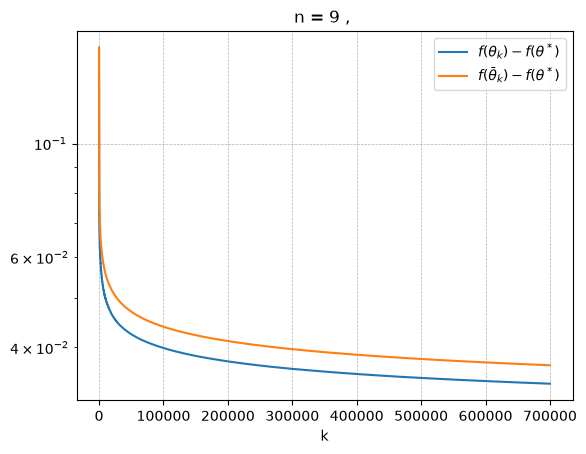

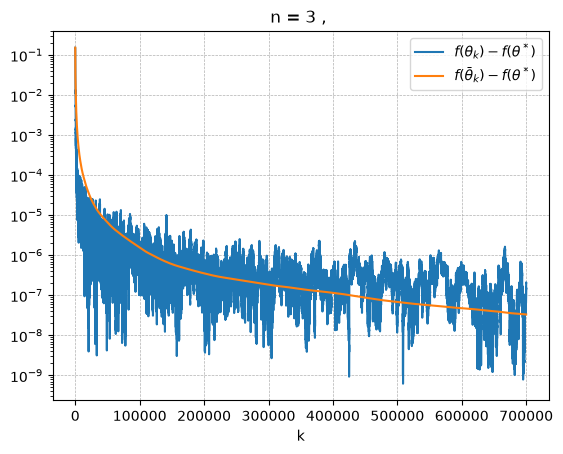

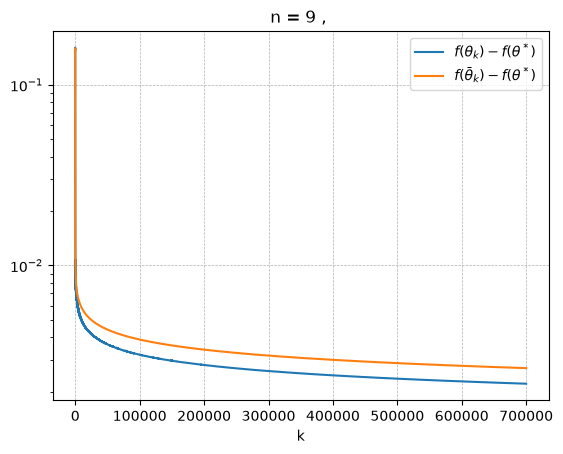

In [4]:
np.random.seed(0)
def gradfi(theta, X, ys):
    N = len(ys)
    i = np.random.randint(0,N)
    return 2*(theta.T@X[i] -ys[i])*X[i]

def SGD(n, gamma, iterations):
    
    X = np.vander(xs, n+1, increasing=True)
    beta = 2/N * np.linalg.norm(X.T @ X, 2)
        
    if N > n+1:
        theta_star = np.linalg.solve(X.T @ X, X.T @ ys)
        f_star = f(theta_star, X, ys)
    else:         
        f_star = 0.0
    
    theta = np.zeros(n+1) # intial guesses
    theta_bar = np.zeros(n+1)
    f_vals, f_bar_vals = [], []
    
    for k in range(iterations):
        theta = theta - gamma(k, beta) * gradfi(theta, X, ys) # updating theta for k>=0
        theta_bar = theta_bar + (theta - theta_bar) / (k + 1) # using the tip and with n = k+1 and simplifying the expression
        f_vals.append(f(theta, X, ys) - f_star)
        f_bar_vals.append(f(theta_bar, X, ys) - f_star)

    plt.figure(dpi=100)
    plt.semilogy(f_vals, label=r'$f(\theta_k) - f(\theta^*)$')
    plt.semilogy(f_bar_vals, label=r'$f(\bar\theta_k) - f(\theta^*)$')
    plt.title(f'n = {n} , ')
    plt.xlabel('k')
    plt.grid(linestyle='dashed', linewidth=0.5)
    plt.legend()
    plt.show()


g1 = lambda k, beta: 0.1/beta
g2 = lambda k, beta: 0.1/(beta*(k+1))
g3 = lambda k, beta: 0.1/(beta*np.floor(k/1000 + 1))
iterations = int(1e5) * N
for g in [g1, g2, g3]:
    SGD(3, g, iterations)
    SGD(9, g, iterations)




---
### Exercise 3: Fitting points in $\mathbb{R}$ using fully connected feedforward neural networks

Again, we consider the data points $\{(x_{i},y_{i})\}_{i=1}^{N}\subseteq\mathbb{R}\times\mathbb{R}$, where $N=7$, below:


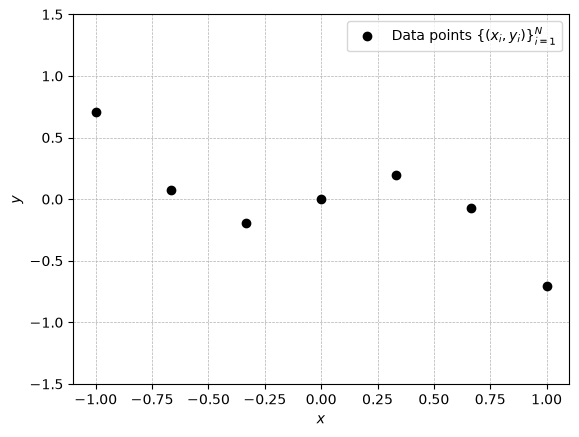

In [5]:
N = 7 # the number of data points
xs = np.linspace(-1, 1, num=N) # the x_i's
ys = np.sin(5*xs)*np.exp(np.abs(2*xs)) / 10 # the y_i's

fig, axes = plt.subplots(dpi=100)
axes.plot(xs,ys,'ko')
axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$'])
axes.set_xlabel('$x$')
axes.set_ylabel('$y$')
axes.grid(linestyle='dashed', linewidth=0.5)
axes.set_ylim([-1.5, 1.5]);

Polynomial fitting as in __Exercise 1__ and __Exercise 2__ gives:

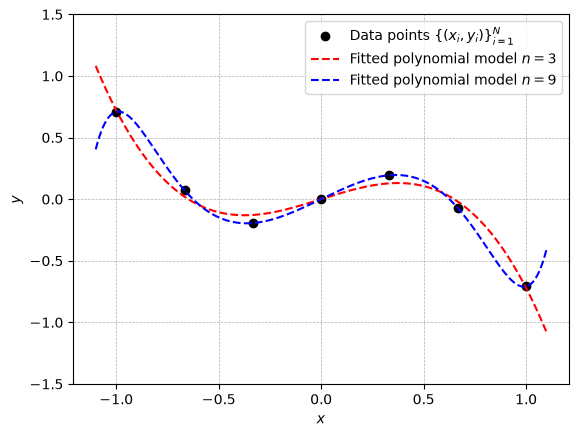

In [6]:
theta_star_n_9 = np.array([0,  0.8, 0, -1.9, 0, -0.583957507, 0, 0.28, 0, 0.695322536])
theta_star_n_3 = np.array([0,  0.523557283,  0, -1.24520755])
x = np.linspace(-1.1, 1.1, num = 1000)

fig, axes = plt.subplots(dpi=100)
axes.plot(xs,ys,'ko')
axes.plot(x, np.polyval(np.flip(theta_star_n_3), x),'r--')
axes.plot(x, np.polyval(np.flip(theta_star_n_9), x),'b--')
axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$', r'Fitted polynomial model $n=3$', r'Fitted polynomial model $n=9$'])
axes.set_xlabel('$x$')
axes.set_ylabel('$y$')
axes.grid(linestyle='dashed', linewidth=0.5)
axes.set_ylim([-1.5, 1.5]);

In this exercise, we are going to explore fitting of these data points using fully connected feedforward neural networks. We will do this by considering the problem

$$
\begin{align}\label{eq:3}\tag{3}
		\underset{\theta}{\mathrm{minimize}} \frac{1}{N}\sum_{i=1}^N L(m(x_i;\theta),y_i)
\end{align}
$$

where $L:\mathbb{R}\times\mathbb{R}\rightarrow\mathbb{R}$ is the least squares loss, i.e.

$$
\begin{align*}
L(u,y) = (u-y)^{2}
\end{align*}
$$

for each $u,y\in\mathbb{R}$ and $m(\cdot;\theta):\mathbb{R}\rightarrow\mathbb{R}$ is a fully connected feedforward neural network model, i.e.

$$
\begin{align*}
m(x;\theta) = W_{D}\sigma_{D-1}(W_{D-1}\sigma_{D-2}(...\sigma_1(W_1 x + b_{1})...)+b_{D-1})+b_{D}	
\end{align*}
$$

for each $x\in\mathbb{R}$, where $\sigma_i$ is an activation functions that act elements-wise, for each $i=1,\ldots,D-1$, and

$$
\begin{align*}
    \theta = (W_{1},b_1,\ldots,W_{D},b_{D})
\end{align*}
$$

such that

$$
\begin{align*}
    \begin{cases}
        W_{1}\in\mathbb{R}^{f_{1} \times 1}& \text{ and }\quad b_{1} \in\mathbb{R}^{f_1}\\	
        W_{i}\in\mathbb{R}^{f_{i} \times f_{i-1}}& \text{ and }\quad b_{i} \in\mathbb{R}^{f_i} \quad\text{ for }\quad i=2,\ldots,D-1 \\
        W_{D}\in\mathbb{R}^{1 \times f_{D-1}}& \text{ and }\quad b_{D} \in\mathbb{R}.
    \end{cases}
\end{align*}
$$

In particular, we will study how the trained model $m(\cdot;\theta)$ depends on:
- The widths ($f_{i}$) and depth ($D$)
- Different activation functions ($\sigma_{i}$)
- Different initial points $\theta_{0}$ used in training
- Different training algorithms such as SGD and and Adam

We will also study:
- How the loss landscape of (3) looks along different directions at an "optimal point" of (3). (Note that we in general have no guarantees that our optimization algorithms will reach a true optimal point of (3) since the problem in nonconvex in general.)

_Remark:_
We will train the models using `pytorch`. `pytorch` is a widely used library or *module* for doing machine learning in python.
It allows the user to construct, train and evaluate neural networks.

- You will need to [install](https://anaconda.org/pytorch/pytorch) `pytorch`

Take a quick look at `pytorch`'s
- [tutorials](https://pytorch.org/tutorials/)
- [documentation](https://pytorch.org/docs/stable/index.html)

---
`pytorch` expects to get data from a `DataLoader` object. Below we create a `DataLoader` and provide it with our data:

In [7]:
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader
from torch import optim

torch_xs = torch.tensor(xs.reshape((N,1)), dtype=torch.float32)
torch_ys = torch.tensor(ys.reshape((N,1)), dtype=torch.float32)
dataset = TensorDataset(torch_xs, torch_ys)
data_loader = DataLoader(dataset, batch_size=len(xs)) # other batch sizes are of course allowed

Typically in `pytorch`, models are defined as a child of the `nn.Module` class. Below, we create a model with:
- Depth $D=2$
- Width $f_1=10$
- ReLU as activation function 

In [8]:
class model(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear1 = nn.Linear(in_features=1, out_features=10)
        self.linear2 = nn.Linear(in_features=10, out_features=1)

    def forward(self, x):
        x = self.linear1(x)
        x = F.relu(x)
        x = self.linear2(x)
        return x

# Create an instance of the model class.
model = model()

In machine learning, the objective function in (3) is sometimes itself called a loss function. In fact, it is already [implemented](https://pytorch.org/docs/stable/generated/torch.nn.MSELoss.html) in `pytorch` and we create the corresponding loss function object below:

In [9]:
loss_fn = nn.MSELoss()

`torch.optim` is a `pytorch` package implementing various optimization algorithms. Below we create an optimizer object that allows us to take a SGD step with step-size/learning rate equal to $0.05$.

In [10]:
optimizer = optim.SGD(model.parameters(), lr=0.05)

Once we have defined the data loader, the model, the loss function and the optimizer as above, we can train the network by simply following these steps in a loop:
1. Sample a batch of data from our dataset
2. Compute the model's prediction on the batch
3. Compute the loss of the prediction w.r.t. ground-truth
4. Backpropagate the loss through the model's parameters
5. Perform one training step.

We will do this for $2000$ epochs.

In [11]:
for epoch in range(2000):
    losses_in_epoch = []
    for batch in data_loader:

        # 1. These are the sampled batches of inputs and ground-truth
        batch_x, batch_y = batch
        
        # 2. Compute the model's prediction on the batch
        pred = model(batch_x)
        
        # 3. Compute the loss of the prediction w.r.t. ground-truth
        loss = loss_fn(pred, batch_y)
        
        # Save losses in a list for averaging later (not sctrictly necessary for batch_size = len(x))
        losses_in_epoch.append(loss)
        
        # 4. Backpropagation
        loss.backward()
        
        # 5. One step of SGD
        optimizer.step()
        
        # Zero the gradients computed in the backpropagation, for starting new optimization step
        optimizer.zero_grad()

    # Every 100th epoch, display progress
    if epoch % 100 == 0:
        print('Epoch: {}\tLoss: {}'.format(epoch, sum(losses_in_epoch)/len(losses_in_epoch)))

Epoch: 0	Loss: 0.18635152280330658
Epoch: 100	Loss: 0.06691647320985794
Epoch: 200	Loss: 0.0628015398979187
Epoch: 300	Loss: 0.05841987952589989
Epoch: 400	Loss: 0.052741535007953644
Epoch: 500	Loss: 0.047324758023023605
Epoch: 600	Loss: 0.04104849323630333


Epoch: 700	Loss: 0.03435683250427246
Epoch: 800	Loss: 0.02807457745075226
Epoch: 900	Loss: 0.022708598524332047
Epoch: 1000	Loss: 0.018376260995864868
Epoch: 1100	Loss: 0.015011927112936974
Epoch: 1200	Loss: 0.012312756851315498
Epoch: 1300	Loss: 0.010133298113942146


Epoch: 1400	Loss: 0.008348429575562477
Epoch: 1500	Loss: 0.006865030620247126
Epoch: 1600	Loss: 0.005633874796330929
Epoch: 1700	Loss: 0.004615190904587507
Epoch: 1800	Loss: 0.0037814078386873007
Epoch: 1900	Loss: 0.0030995155684649944


Below we plot trained model:

Traing loss: 0.00254


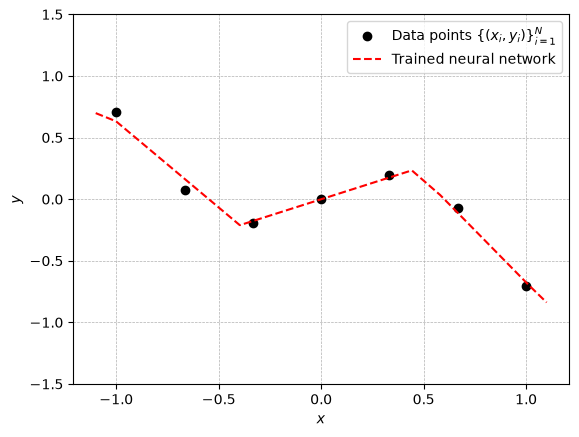

In [12]:
with torch.no_grad():
    x = np.linspace(-1.1, 1.1, num = 1000)
    torch_x = torch.tensor(x.reshape((1000,1)), dtype=torch.float32)
    y_pred = model(torch_x).numpy()
    
    fig, axes = plt.subplots(dpi=100)
    axes.plot(xs,ys,'ko')
    axes.plot(x, y_pred,'r--')
    axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$', r'Trained neural network'])
    axes.set_xlabel('$x$')
    axes.set_ylabel('$y$')
    axes.grid(linestyle='dashed', linewidth=0.5)
    axes.set_ylim([-1.5, 1.5]);
    
    print("Traing loss: {:.5f}".format(loss_fn(model(torch_xs),torch_ys).item()))

__a)__ First, we experiment with the widths ($f_{i}$) and depth ($D$).

Choose widths ($f_{i}$) and depth ($D$) such that:
- the network becomes underparameterized (motive why it is underparameterized)
- the network becomes overparameterized (motive why it is overparameterized)

and train the model as above.

In this subproblem, keep the activation functions fixed as ReLU. However, you are free to experiment with the learning rate and the number of epoch.

How does these two cases differ? Give a qualitative and quantitative analysis.

__Solution:__ 

First we set up a small model with 1 -> 1 and 1 -> 1 connectivity, this in underparametrized since we have $(1*1+1) + (1*1+1) = 4$ parameters which means $N > n+1$, for the other model we have 1 -> 50 and 50 -> 1 which is clearly much more than 7 parameters. We also see a training loss of 0.06769 for the smaller model and 0.00001 for the larger one, showing that the larger overparametrized fits the data much better. This also makes sense with the theory since each parameter increases the expressive capacity, so the larger model is able to fit the data better, we see the small models lack of expressiveness in that it is a straight line.


Epoch: 0	Loss: 1.5445330142974854
Epoch: 100	Loss: 0.08039091527462006
Epoch: 200	Loss: 0.06842632591724396


Epoch: 300	Loss: 0.06774089485406876
Epoch: 400	Loss: 0.06768946349620819
Epoch: 500	Loss: 0.06768937408924103
Epoch: 600	Loss: 0.06768938153982162


Epoch: 700	Loss: 0.06768937408924103
Epoch: 800	Loss: 0.06768937408924103
Epoch: 900	Loss: 0.06768937408924103


Epoch: 1000	Loss: 0.06768937408924103
Epoch: 1100	Loss: 0.06768937408924103
Epoch: 1200	Loss: 0.06768937408924103
Epoch: 1300	Loss: 0.06768937408924103


Epoch: 1400	Loss: 0.06768937408924103
Epoch: 1500	Loss: 0.06768937408924103
Epoch: 1600	Loss: 0.06768937408924103


...

Epoch: 400	Loss: 0.010297616943717003
Epoch: 500	Loss: 0.005766697693616152
Epoch: 600	Loss: 0.003247062908485532
Epoch: 700	Loss: 0.0019046403467655182


Epoch: 800	Loss: 0.001174297882243991
Epoch: 900	Loss: 0.0007506109541282058
Epoch: 1000	Loss: 0.0004889611736871302


Epoch: 1100	Loss: 0.0003204170207027346
Epoch: 1200	Loss: 0.00020975158258806914
Epoch: 1300	Loss: 0.0001368315570289269
Epoch: 1400	Loss: 8.891778270481154e-05


Epoch: 1500	Loss: 5.7597888371674344e-05
Epoch: 1600	Loss: 3.724236012203619e-05
Epoch: 1700	Loss: 2.4085937184281647e-05


Epoch: 1800	Loss: 1.561485078127589e-05
Epoch: 1900	Loss: 1.0242367352475412e-05
Traing loss: 0.00001


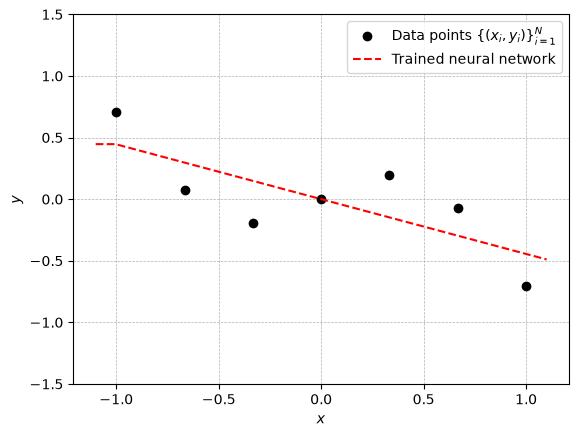

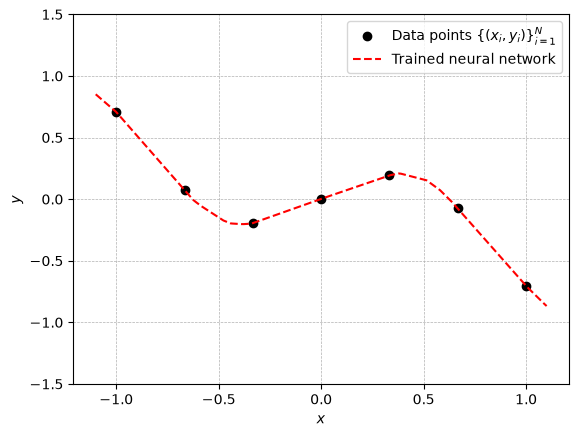

In [13]:
torch.manual_seed(0)
# Write your code here
class smallmodel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear1 = nn.Linear(in_features=1, out_features=1)
        self.linear2 = nn.Linear(in_features=1, out_features=1)

    def forward(self, x):
        x = self.linear1(x)
        x = F.relu(x)
        x = self.linear2(x)
        return x

# Create an instance of the model class.
model = smallmodel()

loss_fn = nn.MSELoss()

optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

for epoch in range(2000):
    losses_in_epoch = []
    for batch in data_loader:

        # 1. These are the sampled batches of inputs and ground-truth
        batch_x, batch_y = batch
        
        # 2. Compute the model's prediction on the batch
        pred = model(batch_x)
        
        # 3. Compute the loss of the prediction w.r.t. ground-truth
        loss = loss_fn(pred, batch_y)
        
        # Save losses in a list for averaging later (not sctrictly necessary for batch_size = len(x))
        losses_in_epoch.append(loss)
        
        # 4. Backpropagation
        loss.backward()
        
        # 5. One step of SGD
        optimizer.step()
        
        # Zero the gradients computed in the backpropagation, for starting new optimization step
        optimizer.zero_grad()

    # Every 100th epoch, display progress
    if epoch % 100 == 0:
        print('Epoch: {}\tLoss: {}'.format(epoch, sum(losses_in_epoch)/len(losses_in_epoch)))

with torch.no_grad():
    x = np.linspace(-1.1, 1.1, num = 1000)
    torch_x = torch.tensor(x.reshape((1000,1)), dtype=torch.float32)
    y_pred = model(torch_x).numpy()
    
    fig, axes = plt.subplots(dpi=100)
    axes.plot(xs,ys,'ko')
    axes.plot(x, y_pred,'r--')
    axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$', r'Trained neural network'])
    axes.set_xlabel('$x$')
    axes.set_ylabel('$y$')
    axes.grid(linestyle='dashed', linewidth=0.5)
    axes.set_ylim([-1.5, 1.5]);

    print("Traing loss: {:.5f}".format(loss_fn(model(torch_xs),torch_ys).item()))

class bigmodel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear1 = nn.Linear(in_features=1, out_features=50)
        self.linear2 = nn.Linear(in_features=50, out_features=1)

    def forward(self, x):
        x = self.linear1(x)
        x = F.relu(x)
        x = self.linear2(x)
        return x

# Create an instance of the model class.
model = bigmodel()

loss_fn = nn.MSELoss()

optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

for epoch in range(2000):
    losses_in_epoch = []
    for batch in data_loader:

        # 1. These are the sampled batches of inputs and ground-truth
        batch_x, batch_y = batch
        
        # 2. Compute the model's prediction on the batch
        pred = model(batch_x)
        
        # 3. Compute the loss of the prediction w.r.t. ground-truth
        loss = loss_fn(pred, batch_y)
        
        # Save losses in a list for averaging later (not sctrictly necessary for batch_size = len(x))
        losses_in_epoch.append(loss)
        
        # 4. Backpropagation
        loss.backward()
        
        # 5. One step of SGD
        optimizer.step()
        
        # Zero the gradients computed in the backpropagation, for starting new optimization step
        optimizer.zero_grad()

    # Every 100th epoch, display progress
    if epoch % 100 == 0:
        print('Epoch: {}\tLoss: {}'.format(epoch, sum(losses_in_epoch)/len(losses_in_epoch)))

with torch.no_grad():
    x = np.linspace(-1.1, 1.1, num = 1000)
    torch_x = torch.tensor(x.reshape((1000,1)), dtype=torch.float32)
    y_pred = model(torch_x).numpy()
    
    fig, axes = plt.subplots(dpi=100)
    axes.plot(xs,ys,'ko')
    axes.plot(x, y_pred,'r--')
    axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$', r'Trained neural network'])
    axes.set_xlabel('$x$')
    axes.set_ylabel('$y$')
    axes.grid(linestyle='dashed', linewidth=0.5)
    axes.set_ylim([-1.5, 1.5]);

    print("Traing loss: {:.5f}".format(loss_fn(model(torch_xs),torch_ys).item()))

__b)__ Second, we will try out different activation functions ($\sigma_{i}$).

Train two overparameterized networks with the same widths and depth, using
- ReLU activation at each layer for one of the networks, and
- 4 * sigmod activation at each layer for the other network.

You are free to experiment with the learning rate and the number of epoch.

How does these two cases differ? Give a qualitative and quantitative analysis.

__Solution:__ 

The sigmoid function, which ranges from 0 to 1 (or in this case 0 to 4 since we have $4* \sigma(x)$) can produce smaller gradients when approaching its upper limit, potentially slowing down training compared to ReLU, which has a constant gradient (1) for positive inputs. Using the learning rate of 0.01 for the sigmoid model, gave us a smoother curve but with a loss of 0.07067. The smoothness is a result of the sigmoids continuos and smooth properties which gives a more polynomial like appearance. On the otherhand, the ReLu with its kink at 0 gives a more piecewise linear appearance. The overparameterized ReLu achieved a loss of 0.01735 due to having strong gradients.


Epoch: 0	Loss: 0.46423959732055664
Epoch: 100	Loss: 0.21544305980205536
Epoch: 200	Loss: 0.08825771510601044
Epoch: 300	Loss: 0.07811810076236725
Epoch: 400	Loss: 0.07423697412014008
Epoch: 500	Loss: 0.07270187139511108


Epoch: 600	Loss: 0.07206127792596817
Epoch: 700	Loss: 0.0717620775103569
Epoch: 800	Loss: 0.07159435003995895
Epoch: 900	Loss: 0.07147818058729172
Epoch: 1000	Loss: 0.07138314843177795
Epoch: 1100	Loss: 0.0712977722287178
Epoch: 1200	Loss: 0.07121774554252625


Epoch: 1300	Loss: 0.07114102691411972
Epoch: 1400	Loss: 0.07106699049472809
Epoch: 1500	Loss: 0.0709952563047409
Epoch: 1600	Loss: 0.0709257498383522
Epoch: 1700	Loss: 0.0708584114909172
Epoch: 1800	Loss: 0.07079274952411652
Epoch: 1900	Loss: 0.0707293376326561


Traing loss: 0.07067
Epoch: 0	Loss: 0.20294561982154846
Epoch: 100	Loss: 0.06972221285104752
Epoch: 200	Loss: 0.06583621352910995
Epoch: 300	Loss: 0.06238458678126335
Epoch: 400	Loss: 0.05916104093194008
Epoch: 500	Loss: 0.05602005869150162
Epoch: 600	Loss: 0.052930183708667755


Epoch: 700	Loss: 0.04986976832151413
Epoch: 800	Loss: 0.04682580381631851
Epoch: 900	Loss: 0.043813418596982956
Epoch: 1000	Loss: 0.040885332971811295
Epoch: 1100	Loss: 0.038139309734106064
Epoch: 1200	Loss: 0.0355064831674099
Epoch: 1300	Loss: 0.0329129621386528


Epoch: 1400	Loss: 0.03036547265946865
Epoch: 1500	Loss: 0.027870655059814453
Epoch: 1600	Loss: 0.025498509407043457
Epoch: 1700	Loss: 0.023292047902941704
Epoch: 1800	Loss: 0.02119550295174122
Epoch: 1900	Loss: 0.019214212894439697
Traing loss: 0.01735
Epoch: 0	Loss: 3.1574149131774902


Epoch: 100	Loss: 0.06976635754108429
Epoch: 200	Loss: 0.0680714100599289
Epoch: 300	Loss: 0.06398939341306686
Epoch: 400	Loss: 0.046832770109176636
Epoch: 500	Loss: 0.016123179346323013


Epoch: 600	Loss: 0.003302894067019224
Epoch: 700	Loss: 0.0016577525530010462
Epoch: 800	Loss: 0.0014333302387967706
Epoch: 900	Loss: 0.0012822257122024894
Epoch: 1000	Loss: 0.0011346808169037104


Epoch: 1100	Loss: 0.0009902754100039601
Epoch: 1200	Loss: 0.0008514479850418866
Epoch: 1300	Loss: 0.0007213111966848373
Epoch: 1400	Loss: 0.0006028887582942843
Epoch: 1500	Loss: 0.0004983955877833068


Epoch: 1600	Loss: 0.0004087021225132048
Epoch: 1700	Loss: 0.0003334141511004418
Epoch: 1800	Loss: 0.0002711903362069279
Epoch: 1900	Loss: 0.0002202510368078947
Traing loss: 0.00018


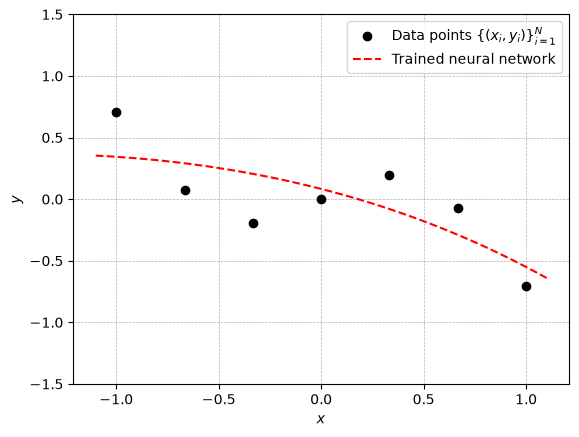

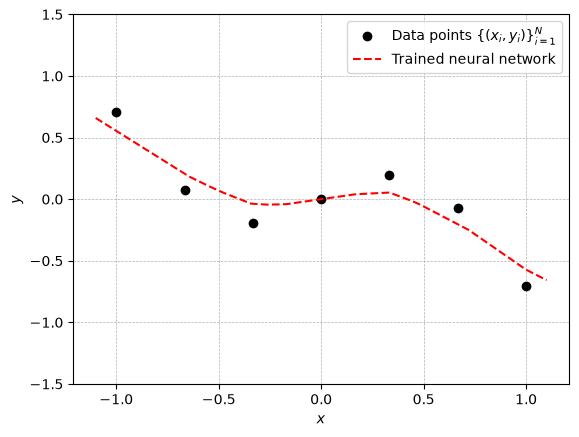

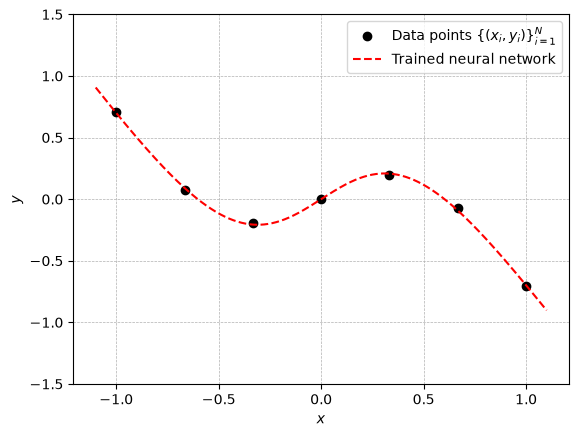

In [14]:
torch.manual_seed(0)
# Write your code here
def train_and_plot(model, loss_fn, optimizer, data_loader):
    for epoch in range(2000):
        losses_in_epoch = []
        for batch in data_loader:
    
            # 1. These are the sampled batches of inputs and ground-truth
            batch_x, batch_y = batch
            
            # 2. Compute the model's prediction on the batch
            pred = model(batch_x)
            
            # 3. Compute the loss of the prediction w.r.t. ground-truth
            loss = loss_fn(pred, batch_y)
            
            # Save losses in a list for averaging later (not sctrictly necessary for batch_size = len(x))
            losses_in_epoch.append(loss)
            
            # 4. Backpropagation
            loss.backward()
            
            # 5. One step of SGD
            optimizer.step()
            
            # Zero the gradients computed in the backpropagation, for starting new optimization step
            optimizer.zero_grad()
    
        # Every 100th epoch, display progress
        if epoch % 100 == 0:
            print('Epoch: {}\tLoss: {}'.format(epoch, sum(losses_in_epoch)/len(losses_in_epoch)))
    
    with torch.no_grad():
        x = np.linspace(-1.1, 1.1, num = 1000)
        torch_x = torch.tensor(x.reshape((1000,1)), dtype=torch.float32)
        y_pred = model(torch_x).numpy()
        
        fig, axes = plt.subplots(dpi=100)
        axes.plot(xs,ys,'ko')
        axes.plot(x, y_pred,'r--')
        axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$', r'Trained neural network'])
        axes.set_xlabel('$x$')
        axes.set_ylabel('$y$')
        axes.grid(linestyle='dashed', linewidth=0.5)
        axes.set_ylim([-1.5, 1.5]);
    
        print("Traing loss: {:.5f}".format(loss_fn(model(torch_xs),torch_ys).item()))
    
class bigmodelsigma(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear1 = nn.Linear(in_features=1, out_features=50)
        self.linear2 = nn.Linear(in_features=50, out_features=1)

    def forward(self, x):
        x = self.linear1(x)
        x = 4 * F.sigmoid(x)
        x = self.linear2(x)
        return x

class bigmodel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear1 = nn.Linear(in_features=1, out_features=50)
        self.linear2 = nn.Linear(in_features=50, out_features=1)

    def forward(self, x):
        x = self.linear1(x)
        x = F.relu(x)
        x = self.linear2(x)
        return x

# Create an instance of the model class.
model = bigmodelsigma()

loss_fn = nn.MSELoss()

optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

train_and_plot(model, loss_fn, optimizer, data_loader)


model = bigmodel()

loss_fn = nn.MSELoss()

optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

train_and_plot(model, loss_fn, optimizer, data_loader)

#sigmoid with adam for task 3d)
model = bigmodelsigma()

loss_fn = nn.MSELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

train_and_plot(model, loss_fn, optimizer, data_loader)
sigmoid_model = model



__c)__ Third, we consider different initial points ($\theta_{0}$) used in training.


For an overparameterized network with ReLU activation functions at each layer and fixed widths and depth, train it with different initial point (note that the constructor of `nn.Module` will initialize the parameters randomly).

Does the initial point affect the final trained network? Give a qualitative and quantitative analysis.

__Solution:__ 

Yes it has an effect. We can see that the graphs look different for all the different initial values, this is because the optimization problem is nonconvec and thus different inital values may lead to different results.


Epoch: 0	Loss: 0.27001529932022095
Epoch: 100	Loss: 0.07334358245134354
Epoch: 200	Loss: 0.06834748387336731
Epoch: 300	Loss: 0.06365309655666351
Epoch: 400	Loss: 0.05919334292411804
Epoch: 500	Loss: 0.05492020770907402
Epoch: 600	Loss: 0.05088416486978531


Epoch: 700	Loss: 0.04707898572087288
Epoch: 800	Loss: 0.04341214895248413
Epoch: 900	Loss: 0.03987463191151619
Epoch: 1000	Loss: 0.036463480442762375
Epoch: 1100	Loss: 0.0332033671438694
Epoch: 1200	Loss: 0.030130844563245773
Epoch: 1300	Loss: 0.027211343869566917


Epoch: 1400	Loss: 0.0244522076100111
Epoch: 1500	Loss: 0.02186170220375061
Epoch: 1600	Loss: 0.01969773881137371
Epoch: 1700	Loss: 0.017789719626307487
Epoch: 1800	Loss: 0.016045164316892624
Epoch: 1900	Loss: 0.014455136843025684
Traing loss: 0.01301
Epoch: 0	Loss: 0.20294561982154846


Epoch: 100	Loss: 0.06972221285104752
Epoch: 200	Loss: 0.06583621352910995
Epoch: 300	Loss: 0.06238458678126335
Epoch: 400	Loss: 0.05916104093194008
Epoch: 500	Loss: 0.05602005869150162
Epoch: 600	Loss: 0.052930183708667755


Epoch: 700	Loss: 0.04986976832151413
Epoch: 800	Loss: 0.04682580381631851
Epoch: 900	Loss: 0.043813418596982956
Epoch: 1000	Loss: 0.040885332971811295
Epoch: 1100	Loss: 0.038139309734106064
Epoch: 1200	Loss: 0.0355064831674099


...

Epoch: 700	Loss: 0.04084499552845955
Epoch: 800	Loss: 0.037431083619594574
Epoch: 900	Loss: 0.034142933785915375
Epoch: 1000	Loss: 0.030933169648051262
Epoch: 1100	Loss: 0.0278590377420187
Epoch: 1200	Loss: 0.024987200275063515
Epoch: 1300	Loss: 0.022256391122937202
Epoch: 1400	Loss: 0.019733205437660217


Epoch: 1500	Loss: 0.0174565427005291
Epoch: 1600	Loss: 0.01538147684186697
Epoch: 1700	Loss: 0.013646409846842289
Epoch: 1800	Loss: 0.01207095105201006
Epoch: 1900	Loss: 0.010638841427862644
Traing loss: 0.00934
Epoch: 0	Loss: 0.21844975650310516
Epoch: 100	Loss: 0.06961572170257568


Epoch: 200	Loss: 0.06576942652463913
Epoch: 300	Loss: 0.062077026814222336
Epoch: 400	Loss: 0.05848650261759758
Epoch: 500	Loss: 0.05496891587972641
Epoch: 600	Loss: 0.05152057483792305
Epoch: 700	Loss: 0.048116087913513184
Epoch: 800	Loss: 0.044834788888692856


Epoch: 900	Loss: 0.04165206104516983
Epoch: 1000	Loss: 0.03861025348305702
Epoch: 1100	Loss: 0.03569961339235306
Epoch: 1200	Loss: 0.032923419028520584
Epoch: 1300	Loss: 0.03024246171116829
Epoch: 1400	Loss: 0.027712507173419
Epoch: 1500	Loss: 0.025482242926955223


Epoch: 1600	Loss: 0.023399805650115013
Epoch: 1700	Loss: 0.021463260054588318
Epoch: 1800	Loss: 0.019683752208948135
Epoch: 1900	Loss: 0.01802959106862545
Traing loss: 0.01649


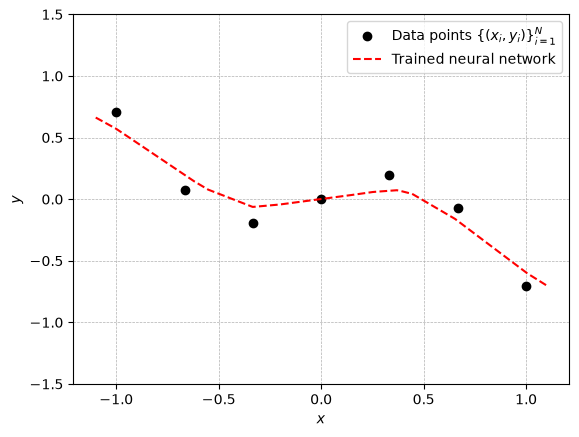

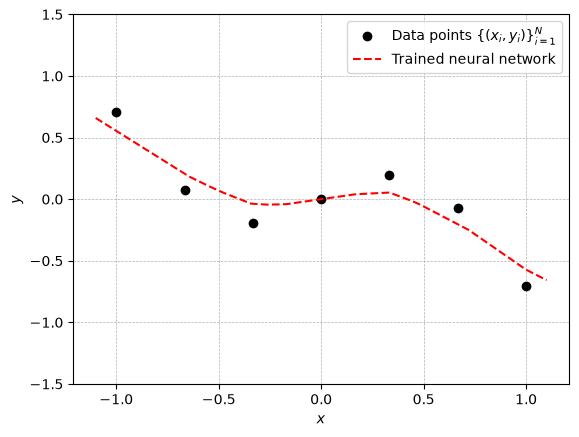

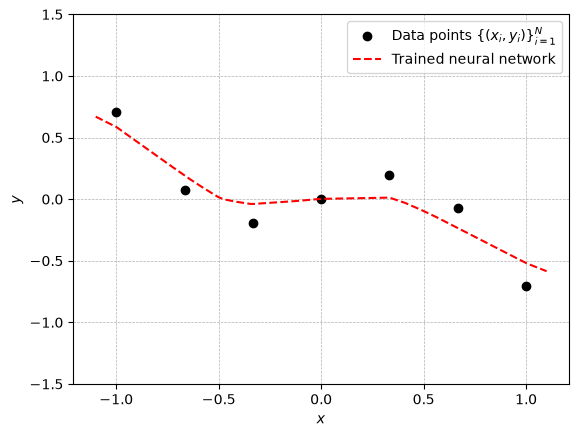

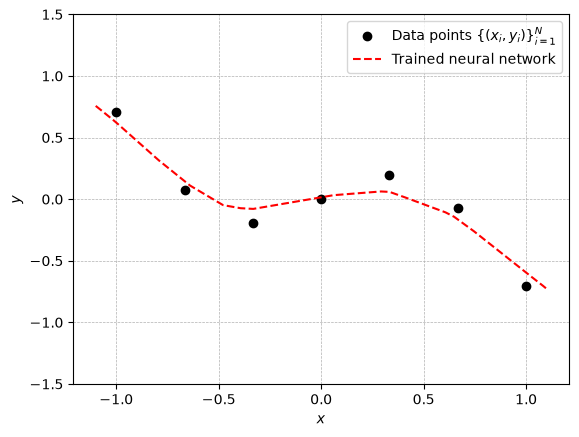

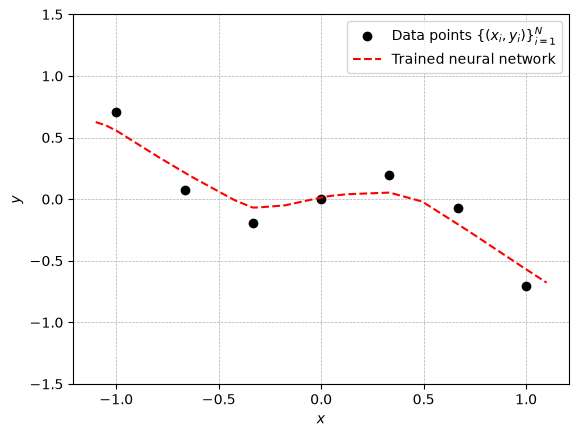

In [15]:
torch.manual_seed(0)
# Hint: The code below prints the parameters of the network 'model'
# for name, param in model.named_parameters():
#    if param.requires_grad:
#        print(name, param.data)

# Write your code here
for i in range(5):
    model = bigmodel()

    loss_fn = nn.MSELoss()

    optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

    train_and_plot(model, loss_fn, optimizer, data_loader)


__d)__ Fourth, we consider different training algorithms.

Compare
- SGD, and
- Adam (`optimizer = optim.Adam(model.parameters(), lr=0.1)`)

for an overparameterized network with ReLU activation functions at each layer and fixed widths and depth.

You are free to experiment with the learning rates and the number of epoch.

How does these two cases differ? Give a qualitative and quantitative analysis.

__Solution:__ 

Adam performs better, achieving a loss of 0.00000 (of order $10^{-9}$) compared to a loss of 0.01301 with SGD. Likely because it uses adaptive learning rates and momentum.


Epoch: 0	Loss: 0.27001529932022095
Epoch: 100	Loss: 0.07334358245134354
Epoch: 200	Loss: 0.06834748387336731
Epoch: 300	Loss: 0.06365309655666351
Epoch: 400	Loss: 0.05919334292411804
Epoch: 500	Loss: 0.05492020770907402
Epoch: 600	Loss: 0.05088416486978531


Epoch: 700	Loss: 0.04707898572087288
Epoch: 800	Loss: 0.04341214895248413
Epoch: 900	Loss: 0.03987463191151619
Epoch: 1000	Loss: 0.036463480442762375
Epoch: 1100	Loss: 0.0332033671438694
Epoch: 1200	Loss: 0.030130844563245773
Epoch: 1300	Loss: 0.027211343869566917


Epoch: 1400	Loss: 0.0244522076100111
Epoch: 1500	Loss: 0.02186170220375061
Epoch: 1600	Loss: 0.01969773881137371
Epoch: 1700	Loss: 0.017789719626307487
Epoch: 1800	Loss: 0.016045164316892624
Epoch: 1900	Loss: 0.014455136843025684
Traing loss: 0.01301


Epoch: 0	Loss: 0.27001529932022095
Epoch: 100	Loss: 0.0011054739588871598
Epoch: 200	Loss: 2.882105150092684e-07
Epoch: 300	Loss: 2.3111144287213392e-07


Epoch: 400	Loss: 1.85424966048231e-07
Epoch: 500	Loss: 1.4368343670412287e-07
Epoch: 600	Loss: 1.0769633718155092e-07
Epoch: 700	Loss: 7.81358409085442e-08
Epoch: 800	Loss: 5.488802656827829e-08


Epoch: 900	Loss: 4.0015797253545315e-07
Epoch: 1000	Loss: 2.4958660915785913e-08
Epoch: 1100	Loss: 3.6931307931808988e-06
Epoch: 1200	Loss: 1.0319095800070954e-08
Epoch: 1300	Loss: 2.476213239788194e-06


Epoch: 1400	Loss: 4.537810127658304e-08
Epoch: 1500	Loss: 2.250887920496325e-09
Epoch: 1600	Loss: 1.6219690905927564e-06
Epoch: 1700	Loss: 4.4643339691674555e-08
Epoch: 1800	Loss: 4.791855245933618e-10


Epoch: 1900	Loss: 4.746547155320968e-09
Traing loss: 0.00000


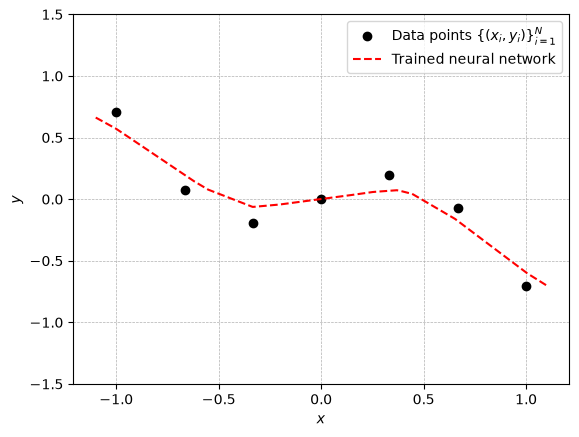

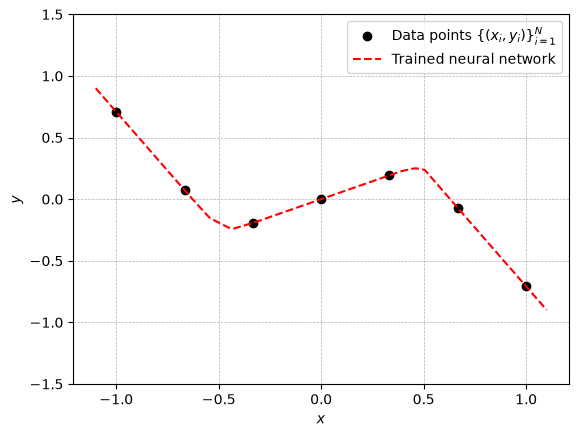

In [16]:
# Write your code here
import copy

torch.manual_seed(0)

model_sgd = bigmodel()
model_adam = copy.deepcopy(model_sgd)

loss_fn = nn.MSELoss()

optimizer_sgd = torch.optim.SGD(model_sgd.parameters(), lr=0.01)
optimizer_adam = torch.optim.Adam(model_adam.parameters(), lr=0.01)

train_and_plot(model_sgd, loss_fn, optimizer_sgd, data_loader)
train_and_plot(model_adam, loss_fn, optimizer_adam, data_loader)

relu_model = model_adam


__e)__ Fifth, we study the loss landscape of a trained network along different directions in parameter space.  


Train an overparameterized network with ReLU activation functions at each layer. Denote it by $m(\cdot,\theta^{*})$ where $\theta^{*}$ are the learned parameters. Sample $\Delta$, with the same size as $\theta^{*}$, from a standard normal distribution (and keep it fixed). Plot 

$$
\begin{align*}
    \frac{1}{N}\sum_{i=1}^N L\left(m\left(x_i;\theta^{*} + t \Delta\right),y_i\right)
\end{align*}
$$

as a function of $t\in[-1,1]$ (or even a larger interval). 

Do the same for another network with the same widths and depth, but using 4 * sigmoid activation functions at each layer. 

How does these two cases differ? Give a qualitative analysis. 

_Hints:_ You can get the parameters as a dictionary of a model by using `model.state_dict()`, updating the parameters in the dictionary, and then loading the updated parameters into the model using `model.load_state_dict(...)`. If you use this approach it is helpful to know the difference between [a shallow copy and a deep copy of a dictionary](https://thispointer.com/python-how-to-copy-a-dictionary-shallow-copy-vs-deep-copy/) You might need to cut off values of the loss that are too high to get a nice plot.

_Optional:_ Plot in two direction at the same time, i.e. plot 
$$
\begin{align*}
    \frac{1}{N}\sum_{i=1}^N L\left(m\left(x_i;\theta^{*} + t \Delta_{t} + s \Delta_{s}\right),y_i\right)
\end{align*}
$$

as a function of $t,s\in[-1,1]$. 

__Solution:__ 

We can see that both functions achieve the lowest value at $t=0$ but we see that sigmoid in generall has a larger loss than Relu.


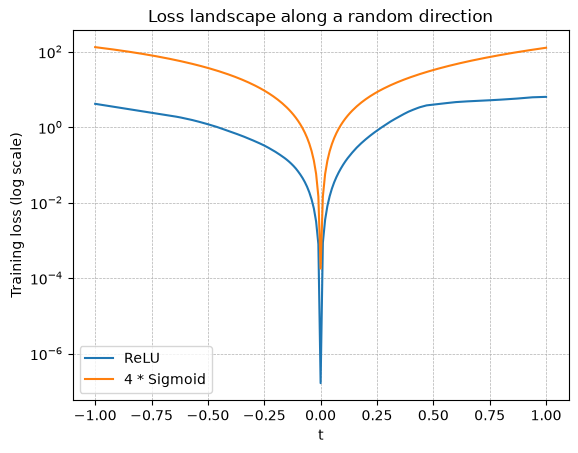

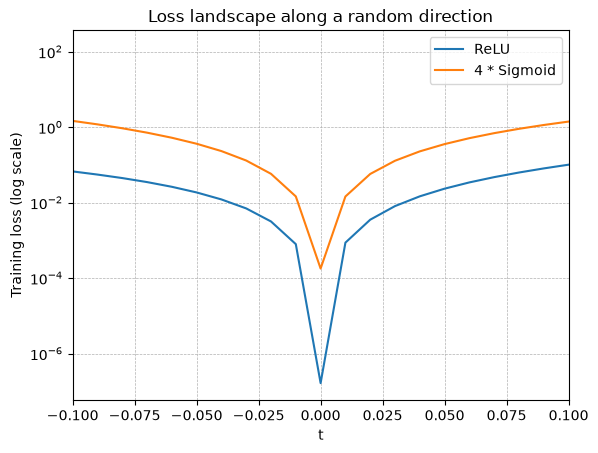

In [17]:
torch.manual_seed(0)
# Write your code here
import copy



def loss_landscape(model, delta, lr=0.01):
    theta_star = copy.deepcopy(model.state_dict())
    ts = np.linspace(-1, 1, 201)
    losses = []

    for t in ts:
        # theta* + t Delta
        new_params = {
            name: theta_star[name] + t * delta[name]
            for name in theta_star
        }

        model.load_state_dict(new_params)

        with torch.no_grad():
            loss = loss_fn(model(torch_xs), torch_ys).item()
            losses.append(loss)

    # Restore original trained parameters
    model.load_state_dict(theta_star)

    return ts, losses
delta = {
        name: torch.randn_like(param)
        for name, param in relu_model.state_dict().items()
    }

# ReLU network
ts, relu_losses = loss_landscape(relu_model,delta)

# 4 * sigmoid network
_, sigmoid_losses = loss_landscape(sigmoid_model, delta)

# Plot both loss landscapes
plt.figure(dpi=100)
plt.semilogy(ts, relu_losses, label="ReLU")
plt.semilogy(ts, sigmoid_losses, label="4 * Sigmoid")

plt.xlabel("t")
plt.ylabel("Training loss (log scale)")
plt.title("Loss landscape along a random direction")
plt.legend()
plt.grid(linestyle="dashed", linewidth=0.5)
plt.show()

plt.figure(dpi=100)
plt.semilogy(ts, relu_losses, label="ReLU")
plt.semilogy(ts, sigmoid_losses, label="4 * Sigmoid")

plt.xlabel("t")
plt.ylabel("Training loss (log scale)")
plt.title("Loss landscape along a random direction")
plt.legend()
plt.grid(linestyle="dashed", linewidth=0.5)
plt.xlim(-0.1, 0.1)
plt.show()

---
### Exercise 4: Implicit regularization via small norm in polynomial fitting in $\mathbb{R}$
_Remark:_ You should solve this exercise using `numpy` primarily.

The purpose of this exercise is to study optimization problems in the overparameterized regime, i.e., when there are multiple solutions to choose from, and see how the norm of a given solution may affect generalization.   

Again, we consider the data points $\{(x_{i},y_{i})\}_{i=1}^{N}\subseteq\mathbb{R}\times\mathbb{R}$, where $N=7$, below:

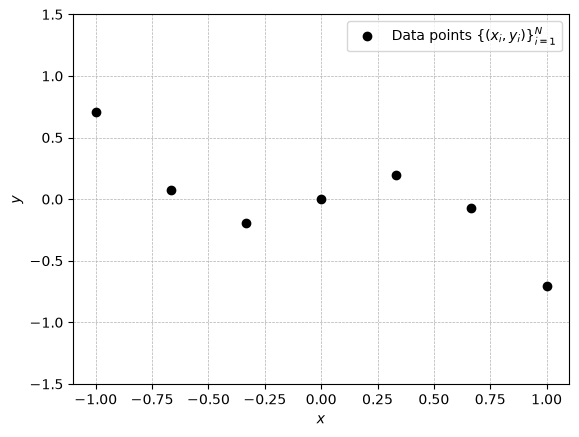

In [18]:
N = 7 # the number of data points
xs = np.linspace(-1, 1, num=N) # the x_i's
ys = np.sin(5*xs)*np.exp(np.abs(2*xs)) / 10 # the y_i's

fig, axes = plt.subplots(dpi=100)
axes.plot(xs,ys,'ko')
axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$'])
axes.set_xlabel('$x$')
axes.set_ylabel('$y$')
axes.grid(linestyle='dashed', linewidth=0.5)
axes.set_ylim([-1.5, 1.5]);

We wish to fit a polynomial model $m(\cdot;\theta)$ of degree $n=9$ (overparameterized) to the data points  $\{(x_{i},y_{i})\}_{i=1}^{N}$. One solution $m(\cdot;\theta^{*})$ is given below:

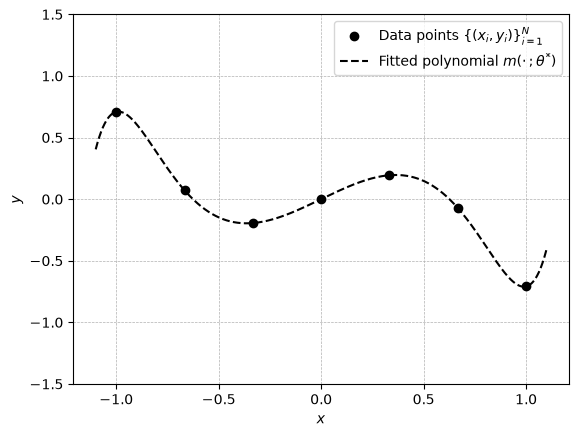

In [19]:
theta_star = np.array([0,  0.8, 0, -1.9, 0, -0.583957507, 0, 0.28, 0, 0.695322536])
x = np.linspace(-1.1, 1.1, num = 1000)

fig, axes = plt.subplots(dpi=100)
axes.plot(xs,ys,'ko')
axes.plot(x, np.polyval(np.flip(theta_star), x),'k--')
axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$', r'Fitted polynomial $m(\cdot\,;\theta^{*})$'])
axes.set_xlabel('$x$')
axes.set_ylabel('$y$')
axes.grid(linestyle='dashed', linewidth=0.5)
axes.set_ylim([-1.5, 1.5]);

---

__a)__ Recall from __Exercise 1__ __g)__ that given a candidate point $a\in\mathbb{R}^{n+1}$, we can obtain a solution via the Euclidean projection formula $\theta^{*} = a - X^{T}(XX^{T})^{-1}(Xa-Y)$. Initialize $a$ randomly and compute the projection $\theta^{*}$ and plot the fitted polynomial $m(\cdot;\theta^{*})$ as above. Vary the magnitude or norm of $\theta^{*}$ indirectly by multiplying $a$ by $0$, $10$, $100$ and $1000$. Visually, how does the generalization of $m(\cdot;\theta^{*})$ correspond to the norm of $\theta^{*}$?

__Solution:__ 

We can see from the graph that as the multiple increases, and thus a, so does the norm of $\theta^*$. This results in a more oscilatory behaivour with larger fluctuations between datapoints since the polynomial coefficient become larger.


2.269426407137996
2.314211119869653
5.067344986155415
45.36429427806902
453.0806111600889


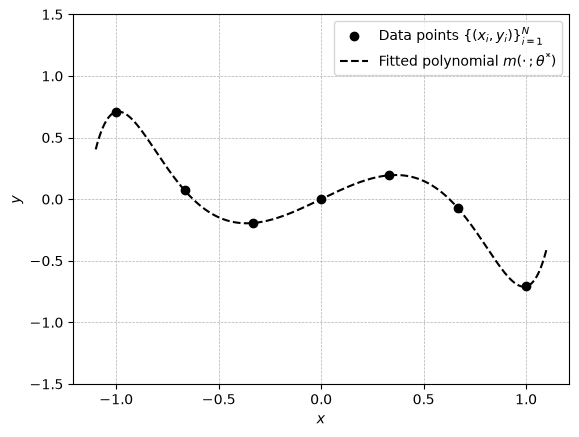

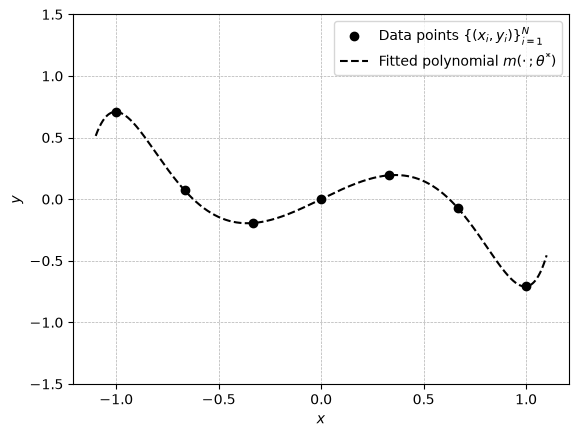

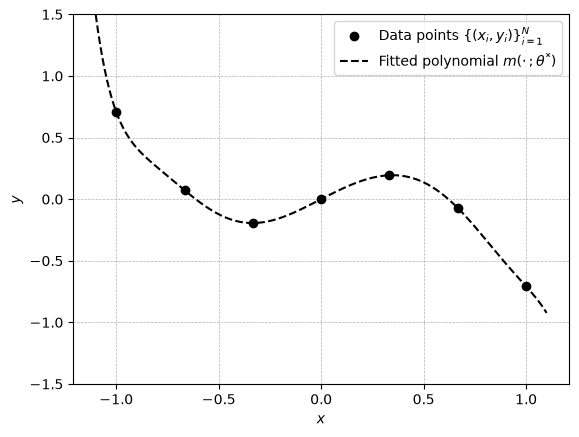

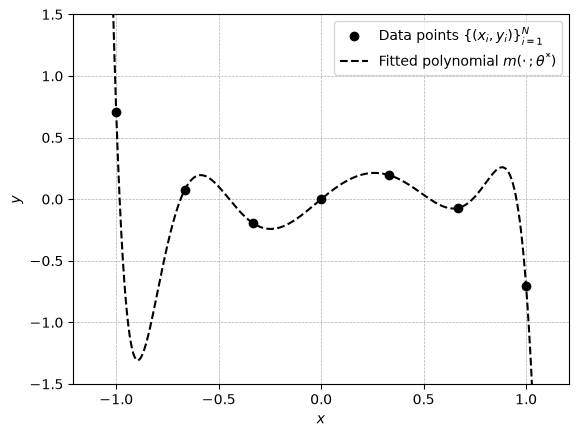

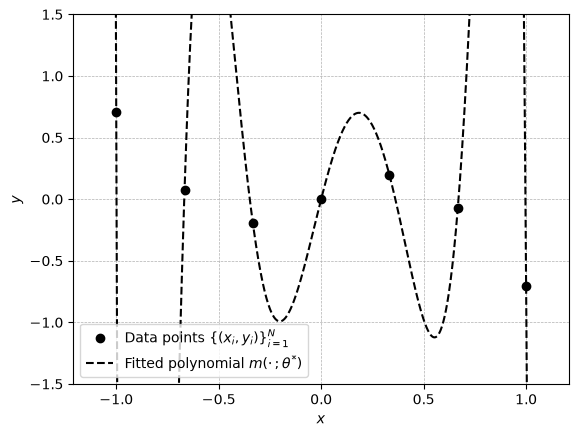

In [20]:
np.random.seed(0)

#a = np.random.randn(n + 1)
#X = np.vander(xs, N=n+1, increasing=True)
#thetastar = a - X.T @ np.linalg.inv(X @ X.T) @ (X @ a - ys)

#x = np.linspace(-1.1, 1.1, num = 1000)

#fig, axes = plt.subplots(dpi=100)
#axes.plot(xs,ys,'ko')
#axes.plot(x, np.polyval(np.flip(thetastar), x),'k--')
#axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$', r'Fitted polynomial $m(\cdot\,;\theta^{*})$'])
#axes.set_xlabel('$x$')
#axes.set_ylabel('$y$')
#axes.grid(linestyle='dashed', linewidth=0.5)
#axes.set_ylim([-1.5, 1.5]);

multiples = [0, 1, 10, 100, 1000]

n = 9 # degree
a_base = np.random.rand(n + 1)

for multiple in multiples:
    
    a = a_base * multiple
    X = np.vander(xs, N=n+1, increasing=True)
    thetastar = a - X.T @ np.linalg.inv(X @ X.T) @ (X @ a - ys)
    
    
    x = np.linspace(-1.1, 1.1, num = 1000)
    print(np.linalg.norm(thetastar, 2))
    fig, axes = plt.subplots(dpi=100)
    axes.plot(xs,ys,'ko')
    axes.plot(x, np.polyval(np.flip(thetastar), x),'k--')
    axes.legend([r'Data points $\{(x_{i},y_{i})\}_{i=1}^{N}$', r'Fitted polynomial $m(\cdot\,;\theta^{*})$'])
    axes.set_xlabel('$x$')
    axes.set_ylabel('$y$')
    axes.grid(linestyle='dashed', linewidth=0.5)
    axes.set_ylim([-1.5, 1.5]);



# Write your code here

__b)__ Implement the GD method for optimization problem (2) in __Exercise 1__ above, starting at $\theta_{0}=0$, using step size $\gamma_{k} = 1/\beta$, and verify that the resulting sequence $\{\theta_{k}\}_{k\geq0}$ converges to $\theta^{*}$, where $\theta^{*}$ is the Euclidean projection starting from the candidate point $a=0$. I.e., the GD method converges to the solution with the smallest norm. Do this by plotting $||\theta_{k}-\theta^{*}||_{2}^{2}$ as a function of $k$ in log-linear scale.

_Remark:_ We consider $\theta_{k}$ to have converged to $\theta^{*}$ if $||\theta_{k}-\theta^{*}||_{2}^{2} \leq 10^{-16}$.


__Solution:__ 



We see that the GD method converges by constant factor, since the plot is a straight line in log scale, and reaches about $10^{-23}$ after around 30000 iterations. Since this is below $10^{-16}$, GD converges to the minimum norm solution $\theta^*$.


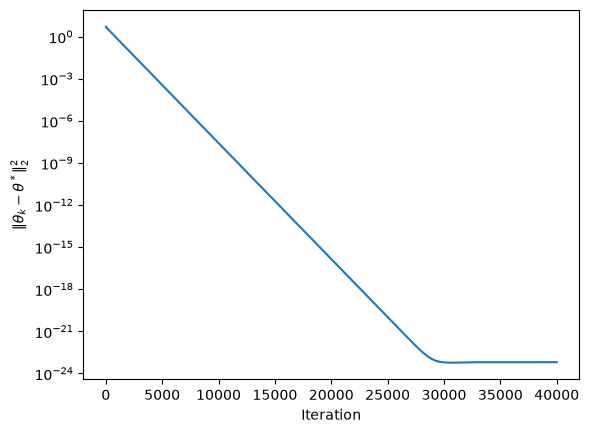

In [21]:
# Write your code here
a = np.zeros(n+1)

X = np.vander(xs, N=n+1, increasing=True)
beta = (2 / N) * np.linalg.norm(X.T @ X, ord=2)
gamma_k = 1 / beta

theta = np.zeros(n+1)

thetalist = []
thetalist.append(theta)

thetastar = a - X.T @ np.linalg.solve(X @ X.T, X @ a - ys)

def gradf(theta, N, X, ys):
    return (2/N) * ((X.T @ X) @ theta - X.T @ ys)

iterations = 40000
for i in range(iterations):
    theta = theta - gamma_k * gradf(theta, N, X, ys)
    thetalist.append(theta)

distances = [np.linalg.norm(t - thetastar)**2 for t in thetalist]

plt.semilogy(distances)
plt.xlabel("Iteration")
plt.ylabel(r"$\|\theta_k - \theta^*\|_2^2$")
plt.show()



---

__c)__ Implement the SGD method for optimization problem (1) in __Exercise 1__ above, starting at $\theta_{0}=0$, using step size $\gamma_{k} = 0.1 / \beta$, and verify that the resulting sequence $\{\theta_{k}\}_{k\geq0}$ converges to $\theta^{*}$, where $\theta^{*}$ is the Euclidean projection starting from the candidate point $a=0$. I.e., the SGD method converges to the solution with the smallest norm. Do this by plotting $||\theta_{k}-\theta^{*}||_{2}^{2}$ as a function of $k$ in log-linear scale.


__Solution:__ 
We see that the SGD method first converges by a constant factor down to about $10^{-9}$ after around 150000 iterations, and then by a slower constant factor, since both parts are straight lines in the log scale. It passes $10^{-16}$ after around $2 * 10^6$ iterations and reaches about $10^{-21}$ after $3* 10^6$ iterations. Therefore we see that SGD also converges to the minimum norm solution $\theta^*$, but slower than GD.

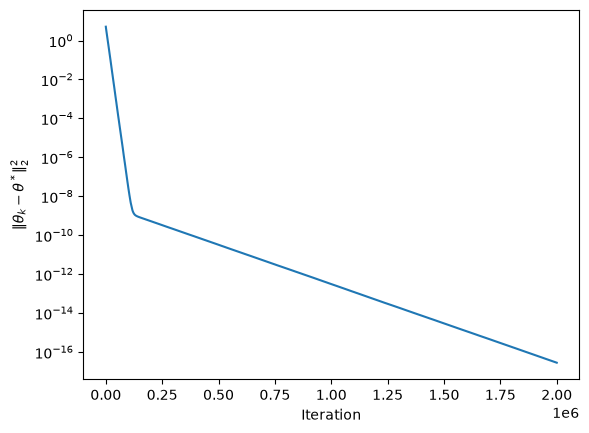

In [22]:
np.random.seed(0)
# Write your code here

a = np.zeros(n+1)

X = np.vander(xs, N=n+1, increasing=True)
beta = (2 / N) * np.linalg.norm(X.T @ X, ord=2)
gamma_k = 0.1 / beta

theta = np.zeros(n+1)

thetalist = []
thetalist.append(theta)

thetastar = a - X.T @ np.linalg.solve(X @ X.T, X @ a - ys)

def gradfi(theta, N, X, ys):
    i = np.random.randint(0,N)
    return 2*(theta.T@X[i] -ys[i])*X[i]

iterations = int(2*1e6)
for i in range(iterations):
    theta = theta - gamma_k * gradfi(theta, N, X, ys)
    thetalist.append(theta)

distances = [np.linalg.norm(t - thetastar)**2 for t in thetalist]

plt.semilogy(distances)
plt.xlabel("Iteration")
plt.ylabel(r"$\|\theta_k - \theta^*\|_2^2$")
plt.show()

---

__d)__ The ADAM optimization method is given by:

- Pick $\theta_{0}\in\mathbb{R}^{n+1}$, $\hat{m}_{0}=\hat{v}_{0}=0\in\mathbb{R}^{n+1}$, $b_{m},b_{v}\in(0,1)$ and $\gamma,\epsilon>0$.
- For $k\geq 0$:
    - Pick $i\in\{1,\ldots, N\}$ uniformly at random
    - Set $g_{k+1} = \nabla f_{i}(\theta_{k})$
    - Set $\hat{m}_{k+1} = b_{m}\hat{m}_{k}+(1-b_{m})g_{k+1}$
    - Set $\hat{v}_{k+1} = b_{v}\hat{v}_{k}+(1-b_{v})g_{k+1}^{2}$ (element-wise square)
    - Set $m_{k+1}=\hat{m}_{k+1}/(1-b_{m}^{k+1})$
    - Set $v_{k+1}=\hat{v}_{k+1}/(1-b_{v}^{k+1})$
    - Set $\theta_{k+1} = \theta_{k} - \gamma m_{k+1} ./ (\sqrt{v_{k+1}} + \epsilon\mathbb{1})$ (element-wise division and square root)

Use the [suggested values](https://arxiv.org/pdf/1412.6980.pdf):

- $b_{m} = 0.9$
- $b_{v} = 0.999$
- $\gamma = 0.001$
- $\epsilon = 10^{-8}$

Implement the ADAM optimization method for optimization problem (1) in __Exercise 1__ above, starting at $\theta_{0}=0$. Does ADAM converge to the minimum norm solution? Plot the resulting model.

__Solution:__ 

We see that ADAM does not converge to minimuim norm solution $\theta^*$, since $\|\theta_k-\theta^*\|_2^2$ levels off at about $6 \cdot 10^{-2}$ after around 17500 iterations instead of going to zero. Visually, we see that ADAMs still fit the polynomial well. 


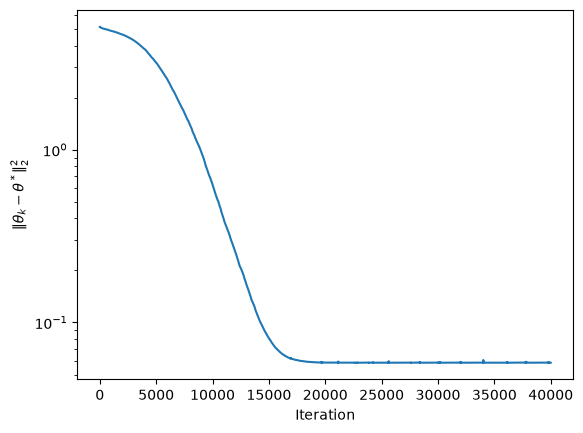

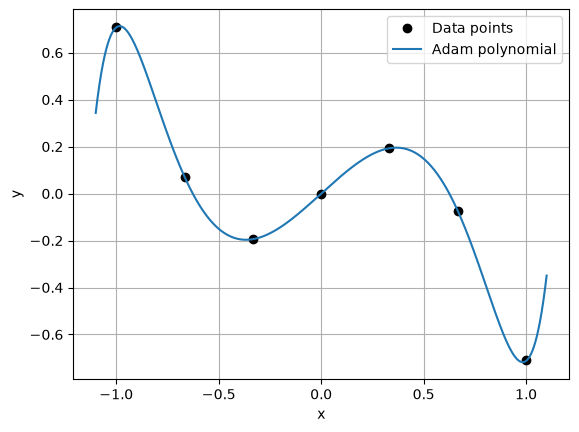

In [23]:
np.random.seed(0)
# Write your code here
def ADAM(theta, N, X, ys, iterations):
    thetalist = []
    thetalist.append(theta)
    bm = 0.9
    bv = 0.999
    gamma = 0.001
    epsilon = 1e-8
    mhat = np.zeros(n+1)
    vhat = np.zeros(n+1)

    for k in range(iterations):
        g_k1 = gradfi(theta, N, X, ys)
        mhat_k1 = bm * mhat + (1 - bm) * g_k1
        vhat_k1 = bv * vhat + (1 - bv) * g_k1**2
        m_k1 = mhat_k1 / (1-bm**(k+1)) #k ??
        v_k1 = vhat_k1 / (1 - bv**(k+1))
        theta = theta - gamma * m_k1 / (np.sqrt(v_k1) + epsilon)
        mhat = mhat_k1
        vhat = vhat_k1
        thetalist.append(theta)
    return thetalist

iterations = int(40000)
theta_0 = np.zeros(n+1)
thetalist = ADAM(theta_0, N, X, ys, iterations)

distances = [np.linalg.norm(t - thetastar)**2 for t in thetalist]

plt.semilogy(distances)
plt.xlabel("Iteration")
plt.ylabel(r"$\|\theta_k - \theta^*\|_2^2$")
plt.show()

x_plot = np.linspace(-1.1, 1.1, 1000)

plt.plot(xs, ys, 'ko', label="Data points")
plt.plot(
    x_plot,
    np.polyval(np.flip(thetalist[-1]), x_plot),
    label="Adam polynomial"
)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid()
plt.show()


---

__e)__ The ADAM optimization method scales the gradient independently in each coordinate. We call such methods diagonally scaled methods. 

Now, recall the scaled projection problem from __Exercise 1__ __g)__ above: given a candidate point $a\in\mathbb{R}^{n+1}$, we can obtain a solution via the scaled projection formula $\theta^{*} = a - H^{-1}X^{T}(X H^{-1} X^{T})^{-1}(Xa-Y)$.


Consider the candidate point $a\in\mathbb{R}^{n+1}$ and the highly skewed diagonal scaling matrix $H\in\mathbb{S}^{n+1}_{++}$ below:

In [24]:
a = np.zeros(n + 1)
H_inv = np.diag(np.logspace(-10, 10, num = n + 1)) # the inverse of H

Plot the data points $\{(x_{i},y_{i})\}_{i=1}^{N}$ and the fitted polynomial $m(\cdot;\theta^{*})$ in the same figure using the scaled projection formula. Visually, does the fitted polynomial $m(\cdot;\theta^{*})$ seem to generalize well?

__Solution:__ 

The fitted polynomial passes through all data points but it does not generalize well, since it oscillates between the outer data points and blows up right oustide of the datapoints. This is because the diagonal of $H^{-1}$ goes from $10^{-10}$ for $\theta_0$ to $10^{10}$ for $\theta_9$, so $H$ is very small for the high order coefficients. Using parts from 1g), with $a=0$, $\|\theta - a\|_H^2 = \sum_i h_i\theta_i^2$, and the larger higher order coefficients costs almost nothing compared to the smaller ones, so the solution puts a lot of weight on terms like $x^9$ which makes it genrelize poorly.

[1.00000000e-10 1.66810054e-08 2.78255940e-06 4.64158883e-04
 7.74263683e-02 1.29154967e+01 2.15443469e+03 3.59381366e+05
 5.99484250e+07 1.00000000e+10]


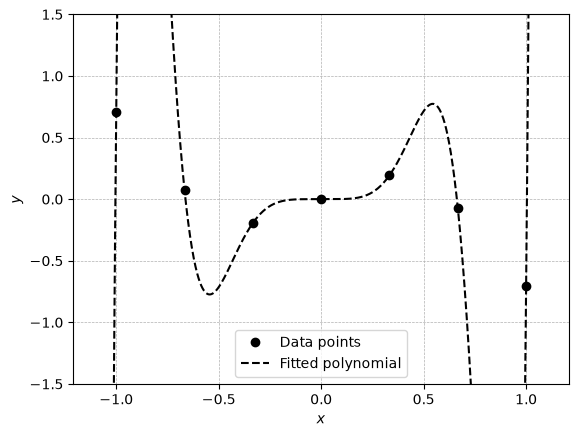

In [25]:
# Write your code here
X = np.vander(xs, N=n+1, increasing=True)

theta_star = a - H_inv @ X.T @ np.linalg.solve(
    X @ H_inv @ X.T, X @ a - ys
)
#print(H_inv)
# The coefficient print, H_inv is zero for all term but the diagonal
print(np.diag(H_inv))
fig, axes = plt.subplots(dpi=100)
axes.plot(xs, ys, 'ko', label="Data points")
axes.plot(x, np.polyval(np.flip(theta_star), x),
          'k--', label="Fitted polynomial")
axes.set_xlabel('$x$')
axes.set_ylabel('$y$')
axes.legend()
axes.grid(linestyle='dashed', linewidth=0.5)
axes.set_ylim([-1.5, 1.5]) 
plt.show()

---

__f)__ The scaled GD method is given by
- Pick $\theta_{0}\in\mathbb{R}^{n+1}$ and $H\in\mathbb{S}_{+}^{n+1}$
- For $k\geq 0$:
    - Set $\theta_{k+1} = \theta_{k} - \gamma_{k} H^{-1}\nabla f(\theta_{k})$ for some $\gamma_{k}>0$.

For numerical reasons (i.e., so that the algorithm converges in reasonable time), consider the less skewed diagonal scaling matrix below:

In [26]:
H_inv = np.diag(np.logspace(-3, 0, num = n + 1)) # the inverse of H

Starting at $\theta_{0}=0$ and using the step size $\gamma_{k}=1/\beta_{H}$, show that the scaled GD method converges to the scaled projection point $\theta^{*}=a - H^{-1}X^{T}(X H^{-1} X^{T})^{-1}(Xa-Y)$ for $a=0$.

Here, $\beta_{H}$ is given by

\begin{align}
    \beta_{H} = \frac{2}{N}\left\lVert H^{-\frac{1}{2}}X^{T}X H^{-\frac{1}{2}} \right\rVert_{2},
\end{align}

where $H^{-\frac{1}{2}}$ is the symmetric square root of $H^{-1}$.

__Solution:__ 

We see that the scaled GD method converges by a constant factor, since the plot is a straight line in log scale. It passes $10^{-16}$ after around 260000 iterations and find a constant value around $6 \cdot 10^{-21}$ after about 350000 iterations. Since this is below $10^{-16}$, scaled GD converges to the scaled projection point $\theta^*$ for $a = 0$


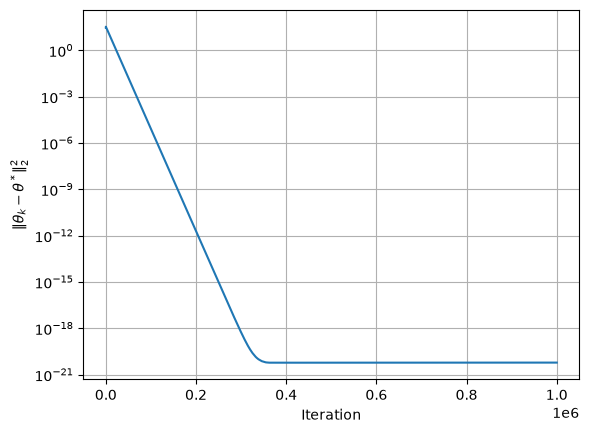

5.994869914140686e-21


In [27]:
# Write your code here
theta = np.zeros(n+1)
thetalist = []
thetalist.append(theta)

a = np.zeros(n+1)

theta_star = a - H_inv @ X.T @ np.linalg.solve(
    X @ H_inv @ X.T, X @ a - ys
)

beta_H = (2/N) * np.linalg.norm(
    np.sqrt(H_inv) @ X.T @ X @ np.sqrt(H_inv), 2
)


gamma_k = 1 / beta_H


for k in range(int(1e6)):
    theta = theta - gamma_k * (H_inv @ gradf(theta, N, X, ys))
    thetalist.append(theta)

distances = [np.linalg.norm(t - theta_star)**2 for t in thetalist]

plt.semilogy(distances)
plt.xlabel("Iteration")
plt.ylabel(r"$\|\theta_k - \theta^*\|_2^2$")
plt.grid()
plt.show()

print(distances[-1])

---
### Exercise 5: Implicit regularization via flatness
_Remark:_ You should solve this exercise using `numpy` primarily.

It has been observed in the [literature](https://arxiv.org/pdf/1609.04836.pdf) that flat mimima tend to lead to better generalization than sharp minima. In this exercise, we empirically verfiy that SGD tends to favour flat mimima.

Consider the finite-sum problem problem
$$
\begin{equation}
\begin{aligned}
& \underset{x\in\mathbb{R}}{\mathrm{minimize}}
& & f(x)= \frac{1}{N} \sum_{i=1}^{N}f_{i}(x)
\end{aligned}
\end{equation}
$$
where the $f_{i}$'s and $f$ are given below: (the derivatives are also given for convenience.)

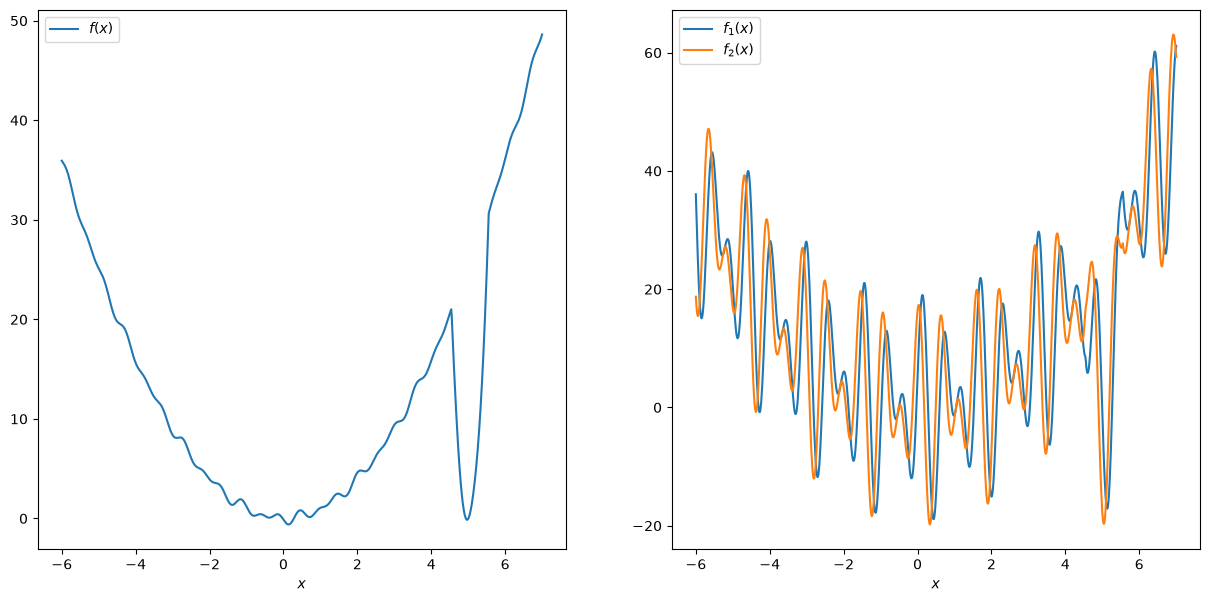

In [28]:
from functools import partial

def loss_term(phase, x):
    if x < 50/11:
        value = x**2
    elif x < 50/9:
        value = 100*(x - 5)**2
    else:
        value = x**2
    return value + 20*np.sin(10*x + phase)*np.cos(2*(x - 5))

def derivative_of_loss_term(phase, x):
    if x < 50/11:
        value = 2*x
    elif x < 50/9:
        value = 200*(x - 5)
    else:
        value = 2*x
    return value + 20*(10*np.cos(10*x + phase)*np.cos(2*(x - 5)) - 2*np.sin(10*x + phase)*np.sin(2*(x - 5)))

N = 2000 # the number of summands
np.random.seed(0)
phases = 2 * np.pi * np.random.rand(N)

# The induvidual summands f_i as a list
f_i_s = list(map(lambda phase : np.vectorize(partial(loss_term, phase)), phases))

# The function f
f = np.vectorize(lambda x : np.mean([f_i(x) for f_i in f_i_s]))

# Derivatives are provided for convenience
derivative_f_i_s = list(map(lambda phase : np.vectorize(partial(derivative_of_loss_term, phase)), phases))
derivative_f = np.vectorize(lambda x : np.mean([d_f_i(x) for d_f_i in derivative_f_i_s]))

x = np.linspace(-6, 7, num=1000)
y_1 = f_i_s[0](x)
y_2 = f_i_s[1](x)
y = f(x)

fig, axes = plt.subplots(1, 2, figsize=(15,7))
axes[0].plot(x, y)
axes[0].legend(["$f(x)$"])
axes[0].set_xlabel('$x$')
axes[1].plot(x, y_1)
axes[1].plot(x, y_2)
axes[1].legend(["$f_{1}(x)$", "$f_{2}(x)$"])
axes[1].set_xlabel('$x$');

Note that the function $f$ has a flat minimum close to $0$ and a sharp minimum close to $5$. Implement both GD and SGD for this problem: 

- Start at $x_{0}=5$, i.e., close to the sharp minimum. 
- Let both GD and SGD go for $2000$ iterations.
- Use the same constant step size $\gamma_{k} = 0.001$ for SGD and GD. 
- You should notice that SDG manages to escape the sharp minimum and find the flat minimum (most of the time), while GD does not. Illustrate this by plotting $x_{k}$ as a function of $k$ for both methods.  (Common mistake: We are not asking for $f(x_k)$ vs $x_k$.)

Give some brief comments.

__Solution:__

We see that GD stays at the sharp minimum close to 5 for all iterations, while SGD escapes after around 700 iterations and reaches the flat minimum after around 1400 iterations. This is because the gradients $f_i'$ in SGD are noisy, which pushes it out of the sharp minimum but not out of the wide flat one.

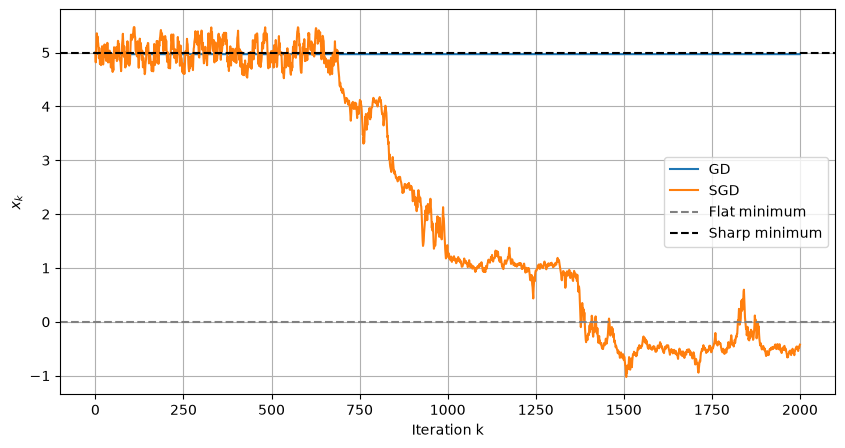

In [29]:
np.random.seed(0)
# Write your code here
x_gd = 5
x_sgd = 5

gamma_k = 0.001

xs_gd = [x_gd]
xs_sgd = [x_sgd]

for k in range(2000):
    x_gd = x_gd - gamma_k * derivative_f(x_gd)
    xs_gd.append(x_gd)

    i = np.random.randint(N)
    x_sgd = x_sgd - gamma_k * derivative_f_i_s[i](x_sgd)
    xs_sgd.append(x_sgd)

plt.figure(figsize=(10, 5))
plt.plot(xs_gd, label="GD")
plt.plot(xs_sgd, label="SGD")
plt.axhline(0, color="gray", linestyle="--", label="Flat minimum")
plt.axhline(5, color="black", linestyle="--", label="Sharp minimum")
plt.xlabel("Iteration k")
plt.ylabel(r"$x_k$")
plt.legend()
plt.grid()
plt.show()